- 매 교시는 **개념 설명 -> 합성음 예제 -> 실제 음성 문제 -> 수강생 작성 칸 -> 정답 코드 및 해설** 순서
  - 합성음으로 원리 확인
  - 실제 목소리를 사용하여 스스로 코드 작성

1교시: 실습1/2 WAV 정보, 정/실수

2교시: 실습3/4 채널 평균, 잡음

3교시: 실습5/6 잘못된 sampling rate, resampling

4교시: 실습7/8 자르기, 저장/재확인

# 2026.10.21(수) 20h~

In [25]:
# %pip install numpy scipy matplotlib ipython

In [76]:
import numpy as np                         # 숫자 배열을 계산하는 도구
import matplotlib.pyplot as plt            # 숫자를 그래프로 보는 도구
from IPython.display import Audio, display # 노트북 안에 재생 버튼을 표시하는 도구
from pathlib import Path                   # 파일 위치를 표현하는 도구
import json                                # 작은 결과 기록을 저장하는 도구
import matplotlib.font_manager as fm

# 그래프에 한글을 표시합니다. 이 준비 코드는 수정하지 않고 실행합니다.
available_fonts = {font.name for font in fm.fontManager.ttflist}
for font_name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if font_name in available_fonts:
        plt.rcParams["font.family"] = font_name
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (10, 3)
plt.rcParams["figure.dpi"] = 110

from scipy.io import wavfile
from math import gcd
from scipy.signal import resample_poly

DATA_DIR = Path("data")
RESULT_DIR = Path("results")
# 실제 녹음 파일은 이 경로로 통일합니다.
VOICE_PATH = DATA_DIR / "my_voice.wav"
VOICE_KEY_MAC_PATH = DATA_DIR / "my_voice(by mac).wav"
VOICE_STEREO_PATH = DATA_DIR / "my_voice_stereo_practice.wav"
# print("준비 완료 / 현재 폴더:", Path.cwd())

`PCM16` = 소리를 압축하지 않고, 한 순간의 소리 크기를 정수 하나로 적어둔 형식

`Pulse Code Modulation` (PCM, 펄스 부호 변조)
- 소리를 일정한 간격으로 재서 숫자로 그대로 저장하는 방식
- MP3처럼 압축하지 않음

### 제공 함수: PCM16 WAV 읽기

In [61]:
def read_pcm16(path):
    """16비트 PCM WAV를 읽어 (SR, 계산용 실수 배열)을 반환합니다."""
    # 파일이 없는 경우 무엇을 준비해야 하는지 알려줍니다.
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"파일이 없습니다: {path}. data 폴더와 파일 이름을 확인하세요.")
    # sr : 샘플링 레이트: 1초당 샘플 수, integers    : 소리의 샘플 값이 담긴 NumPy 배열    [0, 125, -340, ...]
    sr, integers = wavfile.read(path)
    # 32768로 나누는 방식은 16비트 부호 있는 정수 PCM에 적용합니다.
    if integers.dtype != np.int16:
        raise ValueError("이번 실습에는 16비트 정수 PCM WAV를 사용하세요.")
    if sr <= 0 or integers.size == 0:
        raise ValueError("SR이 올바르고 샘플이 들어 있는 WAV가 필요합니다.")
    # 모노는 1차원, 스테레오 등 다채널은 2차원 배열이므로 그 외에는 오류 처리합니다.
    if integers.ndim not in (1, 2):
        raise ValueError("모노 또는 채널 축이 있는 WAV가 필요합니다.")
    # int16 범위 -32768~32767을 -1~약 1 범위의 실수로 바꿉니다.
    # float32 자체가 -1~1로 제한되는 것은 아닙니다.
    sound = integers.astype(np.float32) / 32768.0
    return int(sr), sound

## 1교시. WAV에는 숫자와 읽는 정보가 함께 들어있음

### 실습1. 같은 예제 파일(1강 실습11) 읽기

In [28]:
sample_path = DATA_DIR / "tone_sequence_16k_mono.wav"
sr, audio = read_pcm16(sample_path)
print("파일:", sample_path)
print("SR:", sr)
print("배열 모양:", audio.shape)
# read_pcm16()이 이 정수를 float32 실수로 바꾸고 32768로 나누었기 때문에 계산용 자료형이 float32
# 값은 -1 ~ 1 부근
print("계산용 자료형:", audio.dtype)
print("시간 점의 수:", len(audio))
print("길이:", len(audio) / sr, "초")
display(Audio(audio, rate=sr, normalize=False))

파일: data/tone_sequence_16k_mono.wav
SR: 16000
배열 모양: (32000,)
계산용 자료형: float32
시간 점의 수: 32000
길이: 2.0 초


### 실습2. 정수와 계산용 실수의 관계

In [29]:
from scipy.io import wavfile

# wavfile.read()는 (SR, 파일에 저장된 원래 정수 배열)을 돌려줍니다.
# sample_path = DATA_DIR / "tone_sequence_16k_mono.wav" - 위에서 읽음
file_sr, raw_values = wavfile.read(sample_path)

# 0.25초 지점의 샘플 번호 = 시간 × SR (16000Hz면 4000번), 파일 앞부분?의 무음 구간을 피하기 위해서
start = int(0.25 * file_sr)

# 같은 샘플을 '파일의 정수'와 '계산용 실수(÷32768)' 두 눈금으로 출력합니다.
# 합성음은 0.25초에 위상 0으로 시작하므로 4000번 값이 0입니다.
# 실제 녹음에서는 값 하나가 0이라고 무음이라고 판단할 수 없습니다.
for index in range(start, start + 6):
    print("번호", index,
          "/ 파일 정수", raw_values[index],
          "/ 계산용 실수", round(float(audio[index]), 5))

번호 4000 / 파일 정수 0 / 계산용 실수 0.0
번호 4001 / 파일 정수 1690 / 계산용 실수 0.05157
번호 4002 / 파일 정수 3330 / 계산용 실수 0.10162
번호 4003 / 파일 정수 4871 / 계산용 실수 0.14865
번호 4004 / 파일 정수 6266 / 계산용 실수 0.19122
번호 4005 / 파일 정수 7475 / 계산용 실수 0.22812


### Q. `파일 정수 7475` 와 `계산용 실수 0.22812` 는 각각 무엇이고, 어떻게 구해졌나?

**한 줄 답:** 둘은 **같은 샘플(번호 4005)** 의 값을 **다른 눈금**으로 적은 것입니다. `7475`는 WAV 파일에 저장된 정수, `0.22812`는 그 정수를 `32768`로 나눈 계산용 실수입니다.

#### 1. 각각 무엇인가

| 이름 | 값 | 자료형 | 어디서 왔나 |
|---|---|---|---|
| 파일 정수 | `7475` | `int16` (-32768 ~ 32767) | `wavfile.read()`가 돌려준 `raw_values[4005]`. 파일에 적힌 값 그대로 |
| 계산용 실수 | `0.22812` | `float32` (대략 -1 ~ 1) | `read_pcm16()`이 만든 `audio[4005]`. `round(..., 5)`로 소수 5자리까지만 출력 |

#### 2. 계산용 실수는 어떻게 구해졌나 (`read_pcm16()` 안의 한 줄)

```python
sound = integers.astype(np.float32) / 32768.0
```

`7475 ÷ 32768 = 0.228118...` → 소수 5자리로 반올림하면 `0.22812`.

- **왜 32768인가:** 16비트 정수는 `-32768 ~ 32767`을 표현합니다. 가장 큰 크기 `32768`로 나누면 -1 ~ 거의 1 범위의 실수가 됩니다. (`32767`이 아니라 `32768`로 나누므로 양수 쪽 최댓값은 1보다 아주 조금 작습니다.)
- **왜 바꾸나:** 정수는 파일에 저장하기 좋고, 실수는 계산(곱하기·평균·그래프)하기 편합니다. 뒤에서 진폭 `0~1` 기준으로 생각하려면 이 눈금이 필요합니다.
- **번호 4001~4005도 같은 방식:** `1690÷32768=0.05157`, `3330÷32768=0.10162`, ...

#### 3. 파일 정수 7475는 어떻게 구해졌나

노트북 안에는 이 파일을 만든 코드가 없습니다. 그래서 **파일의 값에서 거꾸로 추정**한 내용입니다(추정).

- 파일의 최댓값 `9830` = `0.3 × 32768 = 9830.4` 이므로 **진폭 A = 0.3**
- 번호 4000이 0이고 다음 값들이 사인 모양으로 늘어나므로 **주파수 f = 440 Hz** (SR = 16000)

이 추정으로 `y[n] = A · sin(2π · f · (n - 4000) / SR)`, 정수 값은 `round(y × 32768)` 로 계산하면 파일의 `[0, 1690, 3330, 4871, 6266, 7475]` 여섯 개와 **전부 일치**했습니다(직접 실행). 번호 4005(0.25초 지점에서 5번째 뒤)는 이렇게 계산됩니다.

```
각도 = 2π × 440 × 5 / 16000 = 0.8639 rad
sin(0.8639) = 0.7604
0.3 × 0.7604 = 0.22812   ← 계산용 실수
0.22812 × 32768 = 7475   ← 파일 정수 (반올림)
```

즉 **파일 정수는 "사인값 × 진폭 0.3 × 32768"을 반올림한 것**, **계산용 실수는 그 정수를 다시 32768로 나눈 것**입니다. 반올림 때문에 두 값이 정확히 같은 눈금으로 돌아오지는 않지만 차이는 1/32768 이하(약 0.00003)입니다.

#### 4. 출력 6줄을 읽는 법

- `번호 4000 → 0`: 0.25초 × 16000 = 4000번째 샘플. 이 합성음은 이 지점에서 위상 0(사인이 0)으로 시작합니다.
- `4001 → 1690, 4002 → 3330, ...`: 사인파가 올라가는 구간이라 값이 커지고, 증가폭(1690, 1640, 1541, 1395, 1209)은 점점 줄어듭니다(사인 곡선이 꼭대기에 가까워지기 때문).
- **주의(★):** 정수든 실수든 "값 하나가 0"이라고 무음은 아닙니다. 사인파는 0을 지나가는 중일 뿐입니다.


### 실제 음성 실습 1. 파일 정보와 샘플값

윈도우 녹음기로 짧은 음성을 녹음한 뒤, 파일의 정보를 확인하고 샘플값을 비교하는 파이썬 코드를 직접 작성하세요.

**변수 이름:** 자동 확인 셀이 검사할 수 있도록 `voice1_sr`, `voice1_raw`(선택한 채널의 정수 배열), `voice1_audio`(정규화한 실수 배열)를 사용하세요.

1. **음성 파일 준비하기**
   - 녹음을 시작한 뒤 약 1초 동안 조용히 기다립니다.
   - “안녕하세요. 음성 데이터 분석 실습입니다.”라고 말합니다.
   - 말을 마친 뒤 약 1초 후 녹음을 종료합니다.
   - 파일은 **16비트 PCM WAV 형식**으로 준비합니다. 다른 형식으로 저장되었다면 변환합니다.
   - 모노와 스테레오 모두 사용할 수 있습니다.
   - 파일 이름을 `my_voice.wav`로 지정하고 작업 노트북과 같은 위치에 있는 `data` 폴더에 넣습니다.

In [30]:
# %pip install imageio-ffmpeg

In [62]:
# PCM16 WAV로 변환하는 코드
import shutil       # 파일 복사와 이동에 사용
import subprocess   # 외부 프로그램인 FFmpeg 실행에 사용

# 변환할 원본 녹음 파일의 경로
SOURCE_PATH = DATA_DIR / "my_recording.m4a"

# True: 작업 계획만 표시 / False: 실제 파일 복사·이동·변환
DRY_RUN = False


def is_pcm16_wav(path):
    """파일을 읽었을 때 샘플 자료형이 16비트 정수인지 확인합니다."""
    try:
        # SR은 사용하지 않으므로 _로 받고, 샘플 배열만 확인합니다.
        _, data = wavfile.read(path)
    except Exception:
        # 파일을 읽을 수 없으면 PCM16 WAV로 판단하지 않습니다.
        return False

    # int16이면 True, 다른 자료형이면 False
    return data.dtype == np.int16


# 기존 my_voice.wav를 보관할 때 사용할 이름
backup_path = DATA_DIR / "my_voice_provided.wav"


# 1. 원본 녹음 파일이 있는지 확인합니다.
if not SOURCE_PATH.is_file():
    print("녹음 파일이 없습니다:", SOURCE_PATH)
    print("이미 data/my_voice.wav를 준비했다면 이 셀은 건너뛰어도 됩니다.")

# 2. 원본과 저장할 파일이 같고, 이미 PCM16 WAV라면 작업하지 않습니다.
# resolve()는 경로를 절대 경로로 정리하여 같은 파일인지 비교하게 합니다.
elif SOURCE_PATH.resolve() == VOICE_PATH.resolve() and is_pcm16_wav(VOICE_PATH):
    print("data/my_voice.wav가 이미 PCM16 WAV입니다. 변환할 필요가 없습니다.")

else:
    # 실행할 작업을 순서대로 저장합니다.
    # 각 항목의 구조: (작업 이름, 원본 경로, 목적지 경로)
    plan = []

    # 3. 저장 위치에 기존 파일이 있고 원본과 다른 파일이면 먼저 보관합니다.
    if VOICE_PATH.is_file() and SOURCE_PATH.resolve() != VOICE_PATH.resolve():

        # 보관 파일까지 이미 있으면 덮어쓰지 않고 중단합니다.
        if backup_path.exists():
            raise FileExistsError(
                f"{backup_path}가 이미 있습니다. "
                "보관할 이름을 직접 정리한 뒤 다시 실행하세요."
            )

        plan.append(("보관", VOICE_PATH, backup_path))

    # 4. 원본이 이미 PCM16 WAV이면 형식 변환 없이 복사합니다.
    if SOURCE_PATH.suffix.lower() == ".wav" and is_pcm16_wav(SOURCE_PATH):
        plan.append(("복사", SOURCE_PATH, VOICE_PATH))

    # M4A 등 다른 형식이거나 PCM16이 아닌 WAV이면 변환합니다.
    else:
        plan.append(("PCM16 WAV로 변환", SOURCE_PATH, VOICE_PATH))

    # 실행할 작업과 파일 경로를 화면에 표시합니다.
    for action, a, b in plan:
        print(f"[{'예정' if DRY_RUN else '실행'}] {action}: {a} → {b}")

    # 5. 확인 모드에서는 파일을 실제로 변경하지 않습니다.
    if DRY_RUN:
        print(
            "\nDRY_RUN = True: 파일을 바꾸지 않았습니다. "
            "내용이 맞으면 False로 바꾸어 다시 실행하세요."
        )

    else:
        # 6. 계획에 기록된 작업을 순서대로 실행합니다.
        for action, a, b in plan:

            if action == "보관":
                # 기존 파일을 보관 경로로 이동합니다.
                shutil.move(a, b)

            elif action == "복사":
                # 원본을 유지하면서 목적지에 같은 내용을 복사합니다.
                shutil.copyfile(a, b)

            else:
                # 음성 파일 변환 프로그램인 FFmpeg의 실행 경로를 가져옵니다.
                import imageio_ffmpeg
                ffmpeg = imageio_ffmpeg.get_ffmpeg_exe()

                # -y            : 출력 파일이 있으면 덮어쓰기 허용
                # -loglevel error: 오류 메시지만 출력
                # -i            : 입력 파일 지정
                # -c:a pcm_s16le : 오디오를 16비트 정수 PCM으로 저장
                # str(b)        : 결과 WAV 파일의 저장 경로
                # check=True    : 변환이 실패하면 예외를 발생시켜 중단
                subprocess.run(
                    [
                        ffmpeg,
                        "-y",
                        "-loglevel", "error",
                        "-i", str(a),
                        "-c:a", "pcm_s16le",
                        str(b)
                    ],
                    check=True
                )

        # 7. 저장된 파일을 다시 읽어 PCM16인지 확인합니다.
        check_sr, check_raw = wavfile.read(VOICE_PATH)

        assert check_raw.dtype == np.int16, (
            "변환 결과가 16비트 PCM이 아닙니다."
        )

        # 최종 파일의 경로, SR, 배열 모양, 자료형을 출력합니다.
        print(
            "\n완료:", VOICE_PATH,
            "/ SR", check_sr,
            "/ 모양", check_raw.shape,
            "/", check_raw.dtype
        )

녹음 파일이 없습니다: data/my_recording.m4a
이미 data/my_voice.wav를 준비했다면 이 셀은 건너뛰어도 됩니다.


2. **파일 읽기 및 기본 정보 출력하기**
   - SciPy의 `wavfile.read()`로 파일을 읽고, 반환값을 변수 두 개에 저장합니다.
   - 샘플링 레이트, 배열 모양, 샘플 자료형을 출력합니다.
   - 배열 모양을 확인하여 모노인지 스테레오인지 판단합니다.
   - 채널당 샘플 수를 샘플링 레이트로 나누어 녹음 길이(초)를 출력합니다.

In [32]:
# 나의 시도
from scipy.io import wavfile

# wavfile.read()는 (SR, 파일에 저장된 원래 정수 배열)을 돌려줍니다.
voice1_path = DATA_DIR / "my_voice.wav" 
voice1_sr, voice1_raw = wavfile.read(sample_path)

print(voice1_sr.shape)
print(voice1_raw.shape)

AttributeError: 'int' object has no attribute 'shape'

# 2026.10.21(수) 21h~

In [63]:
# 1교시 정답 코드_mac terminal에서 명령어로 변환한 파일로 실행(before)
from scipy.io import wavfile

# 1. WAV 파일 읽기
# voice1_sr: 샘플링 레이트(1초당 샘플 수)
# voice1_raw: 파일에 저장된 음성 샘플 배열
voice1_sr, voice1_raw = wavfile.read(VOICE_PATH)

# 2. 파일의 기본 정보 출력
print("샘플링 레이트:", voice1_sr, "Hz")
print("배열 모양:", voice1_raw.shape)
print("샘플 자료형:", voice1_raw.dtype)

# len()은 모노와 스테레오 모두 채널당 샘플 수를 반환합니다.
sample_count = len(voice1_raw)
duration = sample_count / voice1_sr

print("채널당 샘플 수:", sample_count)
print("녹음 길이:", round(duration, 2), "초")

샘플링 레이트: 44100 Hz
배열 모양: (351036, 2)
샘플 자료형: int16
채널당 샘플 수: 351036
녹음 길이: 7.96 초


In [ ]:
# 1. WAV 파일 읽기_강사님께서 제공해주신 PCM16 WAV로 변환하는 코드 실행해서 만든 파일로 실행(after)
# voice1_sr: 샘플링 레이트(1초당 샘플 수)
# voice1_raw: 파일에 저장된 음성 샘플 배열
voice1_sr, voice1_raw = wavfile.read(VOICE_PATH)

# 2. 파일의 기본 정보 출력
print("샘플링 레이트:", voice1_sr, "Hz")
print("배열 모양:", voice1_raw.shape)
print("샘플 자료형:", voice1_raw.dtype)

# len()은 모노와 스테레오 모두 채널당 샘플 수를 반환합니다.
sample_count = len(voice1_raw)
duration = sample_count / voice1_sr

print("채널당 샘플 수:", sample_count)
print("녹음 길이:", round(duration, 2), "초")

샘플링 레이트: 44100 Hz
배열 모양: (385984, 2)
샘플 자료형: int16
채널당 샘플 수: 385984
녹음 길이: 8.75 초


3. **분석할 채널 선택하기**
   - 모노 파일이면 원래 배열을 그대로 사용합니다.
   - 스테레오 파일이면 **왼쪽 채널만 선택**하여 1차원 배열로 만듭니다.
   - 힌트: 배열의 `ndim`으로 차원 수를 확인하고, `[:, 0]`으로 첫 번째 채널을 선택할 수 있습니다.

In [ ]:
if voice1_raw.ndim == 1:
    print("채널: 모노")
else:
    print("채널 수:", voice1_raw.shape[1])
    # 모든 행에서 첫 번째 열(왼쪽 채널)만 선택합니다.
    voice1_raw = voice1_raw[:, 0]

채널 수: 2


4. **계산용 실숫값으로 변환하기**
   - 선택한 음성 샘플 배열을 실수형으로 변환합니다.
   - 각 값을 `32768.0`으로 나누어 정규화한 배열을 만듭니다.

In [ ]:
# 이번 실습의 정규화 기준은 16비트 PCM입니다.
if voice1_raw.dtype.name != "int16":
    raise ValueError("16비트 PCM WAV 파일을 사용해 주세요.")

# 4. 정숫값을 계산용 실숫값으로 변환
# int16의 범위 -32768~32767을 -1.0~약 1.0으로 바꿉니다.
voice1_audio = voice1_raw.astype("float32") / 32768.0

5. **특정 위치의 샘플 6개 출력하기**
   - **0.25초**에 해당하는 샘플 인덱스를 계산합니다.
   - 파일에서 읽은 샘플링 레이트를 사용합니다.
   - 반복문으로 해당 위치부터 연속된 샘플 6개를 출력합니다.
   - 각 줄에 **샘플 번호, 원래 정숫값, 정규화한 실숫값**을 표시합니다.
   - 실숫값은 소수점 다섯째 자리까지 반올림합니다.

6. **무음과 발화 구간 비교하기**
   - 확인할 시간을 **1.5초**로 변경하여 다시 실행합니다.
   - 실제 말하는 위치에 맞게 시간을 조정합니다.
   - 조용한 구간과 말하는 구간의 샘플값을 비교합니다.

In [ ]:
# 5. 0.25초와 1.5초 지점의 샘플값 비교_mac terminal에서 명령어로 변환한 파일로 실행(before)
for check_time in [0.25, 1.5]:

    # 시간(초)에 샘플링 레이트를 곱하여 인덱스를 구합니다.
    start = int(check_time * voice1_sr)

    print(f"\n확인 위치: {check_time}초 / 시작 인덱스: {start}")

    # 확인 위치가 파일 길이를 벗어났는지 검사합니다.
    if start >= len(voice1_raw):
        print("해당 위치에 음성 데이터가 없습니다.")
        continue

    # 파일 끝을 넘지 않도록 최대 6개까지만 출력합니다.
    end = min(start + 6, len(voice1_raw))

    for index in range(start, end):
        print("번호", index,
              "/ 파일 정수", voice1_raw[index],
              "/ 계산용 실수", round(float(voice1_audio[index]), 5))


확인 위치: 0.25초 / 시작 인덱스: 11025
번호 11025 / 파일 정수 0 / 계산용 실수 0.0
번호 11026 / 파일 정수 0 / 계산용 실수 0.0
번호 11027 / 파일 정수 0 / 계산용 실수 0.0
번호 11028 / 파일 정수 -1 / 계산용 실수 -3e-05
번호 11029 / 파일 정수 -1 / 계산용 실수 -3e-05
번호 11030 / 파일 정수 -1 / 계산용 실수 -3e-05

확인 위치: 1.5초 / 시작 인덱스: 66150
번호 66150 / 파일 정수 -1 / 계산용 실수 -3e-05
번호 66151 / 파일 정수 -1 / 계산용 실수 -3e-05
번호 66152 / 파일 정수 1 / 계산용 실수 3e-05
번호 66153 / 파일 정수 1 / 계산용 실수 3e-05
번호 66154 / 파일 정수 1 / 계산용 실수 3e-05
번호 66155 / 파일 정수 0 / 계산용 실수 0.0


In [ ]:
# 5. 0.25초와 1.5초 지점의 샘플값 비교_강사님께서 제공해주신 PCM16 WAV로 변환하는 코드 실행해서 만든 파일로 실행(after)
for check_time in [0.25, 3.5]:

    # 시간(초)에 샘플링 레이트를 곱하여 인덱스를 구합니다.
    start = int(check_time * voice1_sr)

    print(f"\n확인 위치: {check_time}초 / 시작 인덱스: {start}")

    # 확인 위치가 파일 길이를 벗어났는지 검사합니다.
    if start >= len(voice1_raw):
        print("해당 위치에 음성 데이터가 없습니다.")
        continue

    # 파일 끝을 넘지 않도록 최대 6개까지만 출력합니다.
    end = min(start + 6, len(voice1_raw))

    for index in range(start, end):
        print("번호", index,
              "/ 파일 정수", voice1_raw[index],
              "/ 계산용 실수", round(float(voice1_audio[index]), 5))


확인 위치: 0.25초 / 시작 인덱스: 11025
번호 11025 / 파일 정수 0 / 계산용 실수 0.0
번호 11026 / 파일 정수 0 / 계산용 실수 0.0
번호 11027 / 파일 정수 0 / 계산용 실수 0.0
번호 11028 / 파일 정수 -1 / 계산용 실수 -3e-05
번호 11029 / 파일 정수 -1 / 계산용 실수 -3e-05
번호 11030 / 파일 정수 -1 / 계산용 실수 -3e-05

확인 위치: 3.5초 / 시작 인덱스: 154350
번호 154350 / 파일 정수 398 / 계산용 실수 0.01215
번호 154351 / 파일 정수 404 / 계산용 실수 0.01233
번호 154352 / 파일 정수 411 / 계산용 실수 0.01254
번호 154353 / 파일 정수 419 / 계산용 실수 0.01279
번호 154354 / 파일 정수 429 / 계산용 실수 0.01309
번호 154355 / 파일 정수 438 / 계산용 실수 0.01337


**생각해 볼 질문**

- 스테레오 배열에서 `raw_values[0]`과 `raw_values[0, 0]`은 어떻게 다른가요?
- 샘플링 레이트가 48,000Hz라면 0.25초의 샘플 인덱스는 몇 번인가요?
- 조용히 녹음한 구간에도 샘플값이 정확히 0이 아닌 이유는 무엇인가요?
- 샘플 하나의 값이 0이면 무음이라고 판단할 수 있나요?

### 검토 코멘트 — 내 목소리 `my_voice.wav`로 실습 코드를 실행한 결과 (2026-10-21 검토)

아래 수치는 `data/my_voice.wav`를 읽어서 직접 계산한 값입니다. 해석 중 추정은 (추정)으로 표시했습니다.

#### 1. 잘 된 것
- 파일 형식: `44100 Hz`, 모양 `(385984, 2)`, `int16`, 8.75초 → **16비트 PCM WAV 조건 충족**. 강사님 정답 코드가 한 번에 통과했습니다.
- 스테레오 → 왼쪽 채널 선택(`[:, 0]`), `÷32768` 정규화, 인덱스 `int(0.25 × 44100) = 11025`까지 모두 맞습니다.

#### 2. 특이사항 (실행 결과에서 눈여겨볼 것)
| 관찰 | 값 | 해석 |
|---|---|---|
| **왼쪽·오른쪽 채널이 완전히 같음** | `np.array_equal(L, R)` = True | 모노로 녹음된 소리가 스테레오 형식으로 저장된 것으로 보입니다(추정). 그래서 왼쪽만 골라도 정보를 잃지 않습니다. |
| **녹음 소리가 작음** | 최대 절댓값 1782 → 약 0.054 (전체 범위의 5%) | 정상 범위(±1) 안이지만 작습니다. 뒤에서 "정규화(볼륨 키우기)"를 하는 이유가 바로 이것입니다. |
| **말하는 구간** | 약 1.67초 ~ 6.44초 (10ms 단위 RMS > 10 기준, 내 기준값) | 앞 약 1.6초, 뒤 약 2.3초가 조용합니다. 강사님 요청(앞뒤 약 1초)보다 조금 깁니다. 실습에는 지장 없습니다. |
| **조용한 구간의 값이 0이 아님** | 앞 1.5초 안 최대 ±15, 뒤 7초 이후 최대 ±7, 샘플 대부분 -1·0·1 | 마이크·방 잡음(노이즈 바닥) 때문입니다. 질문 "조용한 구간에도 샘플값이 0이 아닌 이유"의 실제 답입니다. |
| **`-3e-05`처럼 보이는 출력** | `-1 ÷ 32768 = -0.0000305…` → `round(…, 5)` → `-3e-05` | 값이 `-0.00003`인데 파이썬이 아주 작은 수를 지수 표기로 보여 준 것입니다. 오류가 아닙니다. |
| `WavFileWarning: Chunk (non-data) not understood` | 읽기 시 경고 1회 | 변환 과정에서 파일 끝에 붙은 부가 정보를 무시했다는 뜻입니다. 샘플값은 정상입니다. |

#### 3. 1.5초 지점이 "말하는 위치"가 아니었습니다
6번 질문은 "실제 말하는 위치에 맞게 시간을 조정"하라고 합니다. 이 녹음은 말이 **약 1.67초**에 시작하므로 1.5초는 **말하기 직전의 조용한 구간**입니다. 출력도 0.25초와 비슷하게 `-1, -1, 1, 1, 1, 0` 정도입니다. 말하는 구간 예시는 이렇습니다.

| 시간 | 시작 인덱스 | 파일 정수 6개 → 실수 |
|---|---|---|
| 0.25초(조용) | 11025 | `0, 0, 0, -1, -1, -1` → 0.0 ~ -0.00003 |
| 1.5초(말하기 직전) | 66150 | `-1, -1, 1, 1, 1, 0` |
| **2.0초(말함)** | 88200 | `-340, -351, -321, -294, -278, -239` → -0.01038 ~ -0.00729 |
| **3.4초(말함)** | 149940 | `-234, -249, -275, -297, -316, -333` → -0.00714 ~ -0.01016 |

말하는 구간은 값이 **수백**, 조용한 구간은 **0 근처(±1~2)** 입니다. 또 말하는 구간의 6개 값은 서로 비슷하게 이어집니다. 샘플 간격이 1/44100초(약 0.023ms)로 매우 짧아서, 파형이 한 샘플 사이에 크게 변하지 않기 때문입니다. 확인하려면 `for check_time in [0.25, 2.0, 3.4]:` 처럼 시간을 바꿔 실행하세요(코드는 직접 바꿔 보세요).

#### 4. 코드 검토 — 고칠 곳
1. **"나의 시도" 셀(13번)이 오류**: `AttributeError: 'int' object has no attribute 'shape'`
   - 원인 ①: `voice1_sr`은 숫자(`int`) 하나라서 `.shape`가 없습니다. `.shape`는 배열(`voice1_raw`)에만 씁니다.
   - 원인 ②: `wavfile.read(sample_path)`는 **합성음 파일**(`tone_sequence_16k_mono.wav`)을 읽습니다. 바로 위에서 만든 `voice1_path`를 쓰려던 것으로 보입니다. `wavfile.read(voice1_path)`로 바꾸면 내 목소리를 읽습니다.
   - 원인 ③(참고): 위 오류 때문에 `print(voice1_raw.shape)`는 실행되지 않았습니다.
2. **9번 셀(PCM16 변환 코드)은 이번 환경에서 실행하면 실패합니다.**
   - `SOURCE_PATH`가 `data/my_recording.m4a`인데 실제 원본은 `data/my_voice.m4a`입니다.
   - `import imageio_ffmpeg`가 이 환경(`voice-ai`)에 없습니다. FFmpeg도 맥에 없습니다(확인함). Mac에서는 터미널 `afconvert -f WAVE -d LEI16 …`로 이미 변환했으므로 **이 셀은 실행하지 않아도 됩니다**(실행 기록도 없음).
   - 주의: 원본 이름을 `my_voice.wav`와 같은 위치·이름으로 바꾸고 실행하면 "기존 파일 보관" 단계가 `my_voice.wav`를 `my_voice_provided.wav`로 **이동**합니다. `DRY_RUN = True`로 먼저 확인하세요.
3. **날짜 제목**: 22번 셀 `# 2026.10.13(화) 20h30~` 은 오늘(2026-10-21, 수)과 맞지 않습니다. 복사 과정에서 남은 것으로 보입니다(추정). 필요하면 고치세요.
4. **2번 셀 출력**에 내 컴퓨터의 전체 경로(`/Users/…`)가 들어 있습니다. 이 저장소는 공개라서, 커밋하기 전에 출력 지우기(Clear Outputs)를 권합니다.

#### 5. 커밋 전 확인
- `data/`가 `.gitignore`에 없어서 지금 `git add`를 하면 **내 목소리 녹음(`my_voice.wav`, `my_voice.m4a`)이 공개 저장소에 올라갑니다.** 먼저 `017_sound/data/`를 무시 목록에 넣을지 정하세요.
- 강사님이 제공한 `tone_sequence_*.wav` 3개는 수업 자료라 올릴지는 따로 정하세요.

#### 6. "생각해 볼 질문"에 대한 이 녹음 기준 답
- **조용한 구간이 정확히 0이 아닌 이유:** 마이크와 주변 소리의 잡음, 그리고 16비트로 반올림하는 양자화 때문입니다. 이 녹음은 ±1~2 정도의 바닥 잡음이 있었습니다.
- **샘플 하나가 0이면 무음인가:** 아닙니다. 말하는 구간에서도 파형이 0을 지나는 순간에는 값이 0일 수 있습니다. 여러 샘플의 크기(예: 구간 RMS)로 봐야 합니다.
- **48,000 Hz에서 0.25초의 인덱스:** `0.25 × 48000 = 12000`번.
- **`raw_values[0]` vs `raw_values[0, 0]`:** 스테레오 배열이면 앞은 첫 샘플의 `[왼쪽, 오른쪽]` 두 값(배열), 뒤는 첫 샘플의 왼쪽 값 하나입니다.

---


## 2교시. 두 채널은 두 배 긴 소리가 아님

### 실습3. 채널 축을 확인하고(stereo) mono로 만들기

In [ ]:
# DATA_DIR 폴더 안에 있는 스테레오 WAV 파일의 경로를 만듭니다.
# DATA_DIR가 Path("data")라면,
# 경로는 data/tone_sequence_22050_stereo.wav가 됩니다.
stereo_path = DATA_DIR / "tone_sequence_22050_stereo.wav"

# 앞에서 직접 정의한 read_pcm16() 함수로 파일을 읽습니다.
# 이 함수는 16비트 정숫값을 약 -1~1 범위의 실숫값으로 변환합니다.
# source_sr: 샘플링 레이트. 22050이면 채널마다 1초에 22,050개를 기록합니다.
# stereo: 왼쪽과 오른쪽 채널의 음성 값이 들어 있는 2차원 배열입니다.
source_sr, stereo = read_pcm16(stereo_path)

# shape는 배열의 모양을 알려줍니다.
# 스테레오 배열의 모양은 (채널당 샘플 수, 채널 수)입니다.
# 예: (44100, 2)이면 행이 44,100개이고 열이 2개입니다.
# 각 행에는 같은 시점의 [왼쪽 값, 오른쪽 값]이 들어 있습니다.
print("stereo 배열의 모양 = (채널당 샘플 수, 채널 수) = ", stereo.shape, "/ SR:", source_sr)

# shape[1]은 열의 개수, 즉 채널 수입니다.
# 스테레오는 왼쪽과 오른쪽의 2채널이므로 2가 출력됩니다.
print("채널 수:", stereo.shape[1])

# shape[0]은 행의 개수, 즉 채널 하나에 저장된 샘플 수입니다.
# 녹음 길이 = 채널당 샘플 수 ÷ 샘플링 레이트
# 예: 44100 ÷ 22050 = 2초
# 좌우 채널은 동시에 녹음된 것이므로 길이를 두 배로 계산하지 않습니다.
print("길이:", stereo.shape[0] / source_sr, "초")

# 배열[행 선택, 열 선택] 형식으로 원하는 데이터를 꺼냅니다.
# :은 모든 행을 선택한다는 뜻입니다.
# 열 번호 0은 왼쪽 채널, 열 번호 1은 오른쪽 채널입니다.
left = stereo[:, 0]     # 모든 시점의 왼쪽 값만 선택 → 1차원 배열
right = stereo[:, 1]    # 모든 시점의 오른쪽 값만 선택 → 1차원 배열
# 현재 합성음은 무음으로 시작해서 무음으로 끝나기 때문에, 화면에 표시된 값이 모두 0
print(left)
print(right)
print(len(left))
print(len(right))
# 0이 아닌 샘플이 몇 개 있는지 확인
print("왼쪽:", np.count_nonzero(left))
print("오른쪽:", np.count_nonzero(right))
# 소리가 있는 0.3초 부근의 샘플 10개 확인
start = int(0.3 * source_sr)
print(left[start:start + 10])
print(right[start:start + 10])

# mean()은 평균을 구하는 함수입니다.
# axis=1은 각 행에서 열 방향으로 평균을 구하라는 뜻입니다.
# 즉, 같은 시점의 (왼쪽 값 + 오른쪽 값) / 2를 계산합니다.
# 예: 한 행이 [0.2, 0.4]라면 모노 값은 0.3이 됩니다.
# 각 행의 값 2개가 평균값 1개로 바뀌면서 1차원 배열이 됩니다.
mono = stereo.mean(axis=1)

# 예: 스테레오 모양이 (44100, 2)이면 모노 모양은 (44100,)입니다.
# (44100,)은 값이 44,100개 들어 있는 1차원 배열이라는 뜻입니다.
# 채널만 하나로 합쳤으므로 시간에 따른 샘플 수와 녹음 길이는 같습니다.
print("모노 모양:", mono.shape, "/ 길이:", len(mono) / source_sr, "초")

stereo 배열의 모양 = (채널당 샘플 수, 채널 수) =  (44100, 2) / SR: 22050
채널 수: 2
길이: 2.0 초
[0. 0. 0. ... 0. 0. 0.]
[0. 0. 0. ... 0. 0. 0.]
44100
44100
왼쪽: 22040
오른쪽: 22040
[0.         0.0375061  0.07443237 0.11019897 0.14422607 0.17599487
 0.20498657 0.23077393 0.2529297  0.27111816]
[0.         0.01876831 0.03723145 0.05508423 0.07211304 0.08798218
 0.10250854 0.11538696 0.12646484 0.13555908]
모노 모양: (44100,) / 길이: 2.0 초


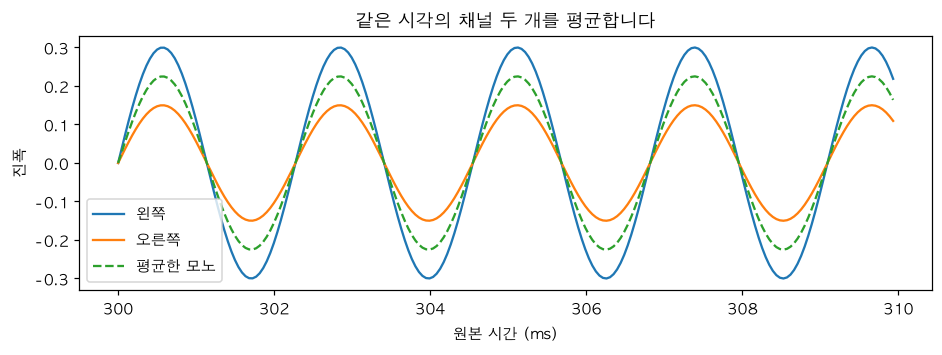

In [ ]:
begin = int(0.30 * source_sr)
end = int(0.31 * source_sr)
zoom_time = np.arange(begin, end) / source_sr * 1000

plt.figure()
plt.plot(zoom_time, left[begin:end], label="왼쪽")
plt.plot(zoom_time, right[begin:end], label="오른쪽")
plt.plot(zoom_time, mono[begin:end], "--", label="평균한 모노")
plt.xlabel("원본 시간 (ms)")
plt.ylabel("진폭")
plt.title("같은 시각의 채널 두 개를 평균합니다")
plt.legend()
plt.show()
display(Audio(mono, rate=source_sr, normalize=False))

In [ ]:
# stereo -> mono 소리가 어떻게 다른지 궁금해서 내가 추가해본 코드
display(Audio(stereo.T, rate=source_sr, normalize=False))

### Q. `display(Audio(stereo, ...))`에서 `error: ushort format requires 0 <= number <= 65535`가 나는 이유

**한 줄 답:** `Audio`는 2차원 배열을 **`(채널 수, 샘플 수)`** 로 읽는데, `stereo`는 **`(샘플 수, 채널 수)`** 모양이라 축이 거꾸로입니다. `stereo.T`로 뒤집어서 넘기면 됩니다.

#### 1. 왜 이런 오류가 나나
- `wavfile.read()` / `read_pcm16()`가 돌려주는 `stereo`의 모양은 `(44100, 2)` = `(채널당 샘플 수, 채널 수)`입니다(바로 위 `stereo.shape` 설명과 같음).
- `IPython.display.Audio`는 2차원 배열을 `(채널 수, 샘플 수)`로 해석합니다. 그래서 `(44100, 2)`를 "채널이 44100개, 샘플이 2개"로 읽습니다.
- `Audio`는 내부에서 WAV 파일을 만들고, 헤더에 **"프레임 하나의 바이트 수"(= 채널 수 × 샘플당 2바이트)** 를 2바이트 부호 없는 정수(`ushort`, 최대 65535)로 기록합니다.
- 채널이 44100개라면 `44100 × 2 = 88200`으로 65535를 넘어서 `ushort format requires 0 <= number <= 65535`가 납니다. (Python `wave.py`의 헤더 쓰기 코드와 IPython `Audio` 소스를 읽고 확인했습니다.)
- 이 환경(`voice-ai`, Python 3.11)에서 같은 파일로 같은 오류를 직접 재현했습니다.

#### 2. 해결

```python
display(Audio(stereo.T, rate=source_sr, normalize=False))
```

- `.T`는 행과 열을 뒤집습니다(전치). `(44100, 2)` → `(2, 44100)`.
- 같은 방식으로 만들어 보면 채널 2개, 22050 Hz, 44100 프레임(2초)의 정상 WAV가 만들어졌습니다(직접 실행).

#### 3. 기억할 점 (★)
| 도구 | 2차원 배열의 모양 |
|---|---|
| `wavfile.read()` (SciPy) | `(샘플 수, 채널 수)` |
| `Audio(...)` (IPython) | `(채널 수, 샘플 수)` |

- 두 도구의 기본 모양이 반대라서, 스테레오를 재생할 때는 `.T`가 필요합니다.
- 1차원(모노) 배열은 모양 문제가 없습니다. 바로 위 `Audio(mono, ...)`가 오류 없이 되는 이유입니다.
- 이 셀은 강사님이 제공하신 코드를 그대로 두었습니다. 아래 셀에서 `.T`를 직접 붙여 실행해 보세요.


### 실습4. 원본과 잡음이 섞인 예제 비교 (clean vs noisy data)

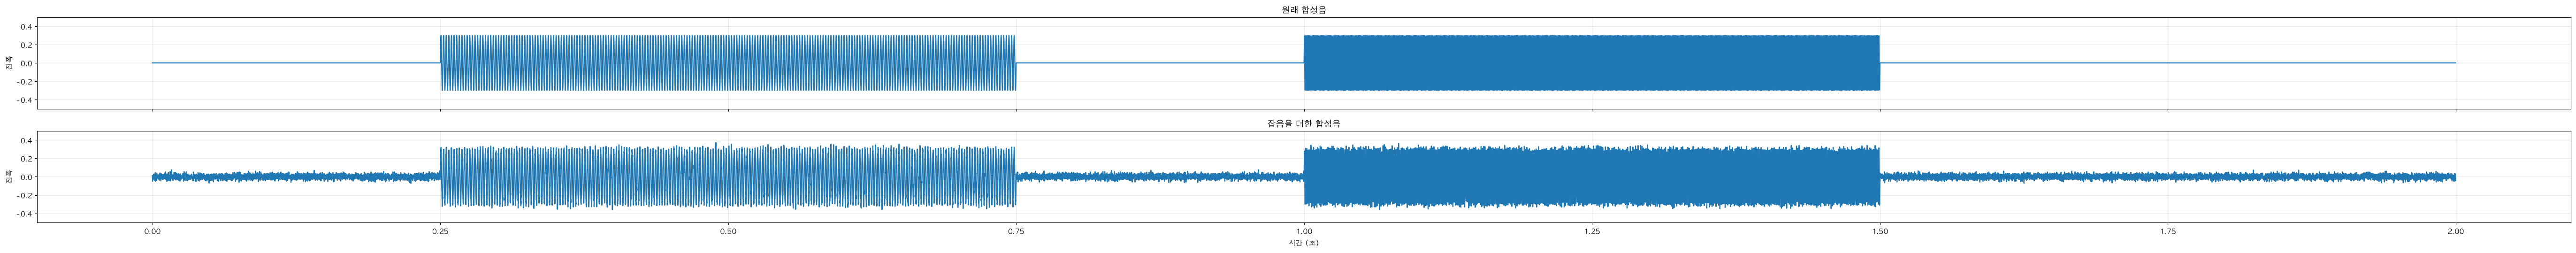

원래 합성음


잡음을 더한 합성음


In [36]:
# 잡음이 없는 합성음과 잡음을 더한 합성음을 각각 읽습니다.
# 반환값: 샘플링 레이트(SR), 계산용 실수 배열
clean_sr, clean = read_pcm16(DATA_DIR / "tone_sequence_16k_mono.wav")
noisy_sr, noisy = read_pcm16(DATA_DIR / "tone_sequence_noisy_16k_mono.wav")

# 위아래로 그래프 2개를 만들고, 시간축과 진폭축을 공유합니다.
# 같은 눈금으로 표시하여 두 파형을 비교하기 쉽게 합니다.
fig, axes = plt.subplots(2, 1, figsize=(50, 5), sharex=True, sharey=True) # 강사님 제공 코드에서는 figsize 가로 10이었는데, 가로 늘려서 직사각형이 사실은 수많은 파동으로 이루어진 거라는 걸 보고 싶어서 바꿔봄..

# 그래프 위치, 음성 배열, SR, 제목을 하나씩 묶어 두 번 반복합니다.
for ax, sound, rate, title in zip(
    axes,
    [clean, noisy],
    [clean_sr, noisy_sr],
    ["원래 합성음", "잡음을 더한 합성음"]
):
    # 샘플 번호를 해당 파일의 SR로 나누어 초 단위 시간축을 만듭니다.
    # 가로축은 시간, 세로축은 각 샘플의 값입니다.
    ax.plot(np.arange(len(sound)) / rate, sound)

    # 제목과 세로축 이름을 지정하고, 진폭 표시 범위를 고정합니다.
    # ylim은 그래프의 표시 범위만 바꾸며 음성 데이터는 바꾸지 않습니다.
    ax.set(title=title, ylabel="진폭", ylim=(-0.5, 0.5))

    # 파형을 비교하기 쉽도록 연한 격자를 표시합니다.
    ax.grid(alpha=0.3)

# 아래쪽 그래프에 공통 가로축 이름을 표시합니다.
axes[1].set_xlabel("시간 (초)")

# 제목과 축 이름이 겹치지 않도록 간격을 조정한 뒤 출력합니다.
plt.tight_layout()
plt.show()

# 원래 합성음을 해당 파일의 SR로 재생합니다.
# normalize=False: 자동으로 크기를 조정하지 않아 원래 진폭으로 비교합니다.
print("원래 합성음")
display(Audio(clean, rate=clean_sr, normalize=False))

# 잡음을 더한 합성음을 재생하여 차이를 직접 들어 봅니다.
# 특히 원래 무음이었던 구간에서도 잡음이 들리는지 확인합니다.
print("잡음을 더한 합성음")
display(Audio(noisy, rate=noisy_sr, normalize=False))

# 2026.10.21(수) 22h~

### 숫자로 비교하기 - `RMS`

In [37]:
def rms(x):
    """구간의 평균적인 크기: 제곱 → 평균 → 제곱근"""
    return float(np.sqrt(np.mean(np.square(x))))

# 합성음은 0~0.25초가 무음, 0.25~0.75초가 440Hz 구간입니다.
quiet = slice(0, int(0.25 * clean_sr))
tone = slice(int(0.25 * clean_sr), int(0.75 * clean_sr))

for name, sound in [("원래 합성음", clean), ("잡음 합성음", noisy)]:
    print(f"{name} / 무음 구간 RMS {rms(sound[quiet]):.4f} / 440Hz 구간 RMS {rms(sound[tone]):.4f}")

원래 합성음 / 무음 구간 RMS 0.0000 / 440Hz 구간 RMS 0.2121
잡음 합성음 / 무음 구간 RMS 0.0200 / 440Hz 구간 RMS 0.2133


In [ ]:
# 내가 추가한 코드 -> 주파수가 더 높은 소리 구간도 RMS 값은 비슷하네.. RMS의 의미를 아직 정확하게는 이해 못했지만..
quiet2 = slice(int(0.75 * clean_sr), int(1 * clean_sr))
tone2 = slice(int(1 * clean_sr), int(1.5 * clean_sr))

for name, sound in [("원래 합성음", clean), ("잡음 합성음", noisy)]:
    print(f"{name} / 무음 구간 RMS {rms(sound[quiet2]):.4f} / 440Hz 구간 RMS {rms(sound[tone2]):.4f}")

원래 합성음 / 무음 구간 RMS 0.0000 / 440Hz 구간 RMS 0.2121
잡음 합성음 / 무음 구간 RMS 0.0202 / 440Hz 구간 RMS 0.2132


### 합성음 관찰 정리

### 실제 음성 실습2. 좌우 분리, mono 변환..

my_voice.wav를 불러와 왼쪽·오른쪽 채널을 분리하고, 두 채널을 평균하여 모노로 변환하는 코드

In [ ]:
# 정답 코드
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Audio, display

# 1. 음성 파일 읽기
# read_pcm16()이 실수 변환과 정규화를 수행하므로
# 여기서 다시 32768로 나누지 않습니다.
# 첫 실행은 원본 녹음/내 목소리, 두 번째 실행은 아래 줄을 VOICE_STEREO_PATH로 변경합니다.
channel_path = VOICE_PATH # 내 목소리 online recording
# channel_path = VOICE_STEREO_PATH
# channel_path = VOICE_KEY_MAC_PATH
my_sr, my_stereo = read_pcm16(channel_path)

# 이번 실습에서는 좌우 채널이 있는 스테레오 파일을 사용합니다.
if my_stereo.ndim != 2 or my_stereo.shape[1] != 2:
    raise ValueError("이번 실습에는 스테레오(2채널) 파일을 사용하세요.")

print("파일:", channel_path.name)
print("좌우 값이 모두 같은가?:", np.array_equal(my_stereo[:, 0], my_stereo[:, 1])) # 왼 vs 오른쪽
print("샘플링 레이트:", my_sr, "Hz") # windows 녹음기에서는 48000Hz가 기본?
print("스테레오 배열 모양:", my_stereo.shape)
print("채널 수:", my_stereo.shape[1])

# 행 개수는 채널 하나에 저장된 샘플 수입니다.
my_duration = my_stereo.shape[0] / my_sr
print("변환 전 길이:", my_duration, "초")

# 2. 왼쪽·오른쪽 채널 분리
# :은 모든 행을 선택한다는 뜻입니다.
my_left = my_stereo[:, 0]     # 첫 번째 열: 왼쪽 채널
my_right = my_stereo[:, 1]    # 두 번째 열: 오른쪽 채널

print("\n왼쪽 배열 모양:", my_left.shape)
print("오른쪽 배열 모양:", my_right.shape)

파일: my_voice.wav
좌우 값이 모두 같은가?: False
샘플링 레이트: 44100 Hz
스테레오 배열 모양: (351036, 2)
채널 수: 2
변환 전 길이: 7.96 초

왼쪽 배열 모양: (351036,)
오른쪽 배열 모양: (351036,)


In [65]:
# 3. 좌우 채널을 평균하여 모노로 변환
# 각 행에서 (왼쪽 값 + 오른쪽 값) / 2를 계산합니다.
# 같은 시점의 값 두 개가 하나로 합쳐집니다.
my_mono = my_stereo.mean(axis=1)

print("\n모노 배열 모양:", my_mono.shape)
print("변환 후 길이:", len(my_mono) / my_sr, "초")
print("변환 전후 길이가 같은가?:",
      my_stereo.shape[0] == len(my_mono))


모노 배열 모양: (351036,)
변환 후 길이: 7.96 초
변환 전후 길이가 같은가?: True



1.5초 지점의 샘플 비교
번호 66150 / 왼쪽 0.00000 / 오른쪽 0.00000 / 모노 0.00000
번호 66151 / 왼쪽 -0.00003 / 오른쪽 -0.00003 / 모노 -0.00003
번호 66152 / 왼쪽 -0.00003 / 오른쪽 -0.00003 / 모노 -0.00003
번호 66153 / 왼쪽 -0.00003 / 오른쪽 -0.00003 / 모노 -0.00003
번호 66154 / 왼쪽 -0.00003 / 오른쪽 -0.00003 / 모노 -0.00003
번호 66155 / 왼쪽 -0.00003 / 오른쪽 0.00000 / 모노 -0.00002
모노 값이 좌우 평균과 같은가?: True


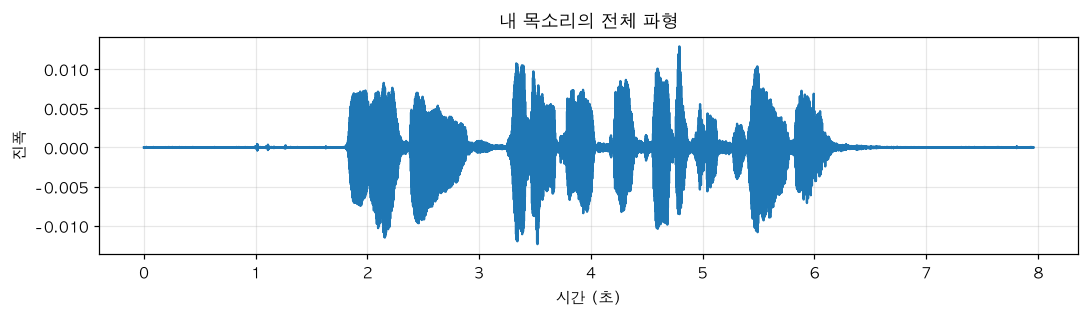

In [66]:
# 4. 1.5초 지점부터 연속된 샘플 6개 비교
check_time = 1.5
start = int(check_time * my_sr)

print(f"\n{check_time}초 지점의 샘플 비교")

if start >= len(my_mono):
    print("파일이 짧습니다. check_time을 더 작은 값으로 바꾸세요.")
else:
    # 파일 끝을 넘지 않도록 출력 범위를 제한합니다.
    end = min(start + 6, len(my_mono))

    for index in range(start, end):
        print(
            f"번호 {index}"
            f" / 왼쪽 {my_left[index]:.5f}"
            f" / 오른쪽 {my_right[index]:.5f}"
            f" / 모노 {my_mono[index]:.5f}"
        )

    # 두 채널을 더하고 2로 나눈 결과와 비교합니다.
    # 실수 계산이므로 아주 작은 오차를 허용하는 allclose()를 사용합니다.
    expected = (my_left[start:end] + my_right[start:end]) / 2
    print("모노 값이 좌우 평균과 같은가?:",
          np.allclose(my_mono[start:end], expected))


# 5-1. 모노 음성의 전체 파형
# 샘플 번호를 SR로 나누면 각 샘플의 시간(초)이 됩니다.
my_time = np.arange(len(my_mono)) / my_sr

plt.figure(figsize=(10, 3))
plt.plot(my_time, my_mono)
plt.xlabel("시간 (초)")
plt.ylabel("진폭")
plt.title("내 목소리의 전체 파형")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

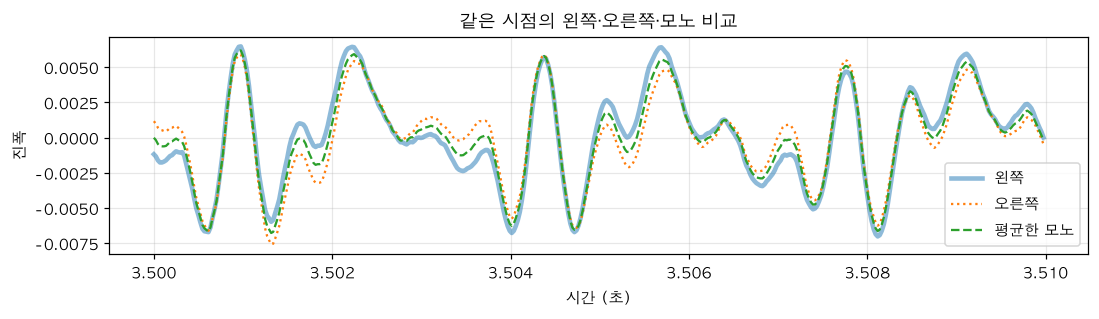

In [67]:
# 5-2. 말하는 구간 중 0.01초를 확대하여 세 파형 비교
# 위 전체 파형을 보고 소리가 있는 시간으로 수정하세요.
zoom_start = 3.5
zoom_end = zoom_start + 0.01

if not (0 <= zoom_start < zoom_end <= my_duration):
    print("확대할 시작과 끝 시간을 파일 길이 안으로 지정하세요.")
else:
    begin = int(zoom_start * my_sr)
    end = int(zoom_end * my_sr)

    # 원본 파일 기준의 시간(초)을 사용합니다.
    zoom_time = np.arange(begin, end) / my_sr

    plt.figure(figsize=(10, 3))
    plt.plot(zoom_time, my_left[begin:end],
             label="왼쪽", linewidth=3, alpha=0.5)
    plt.plot(zoom_time, my_right[begin:end],
             label="오른쪽", linestyle=":")
    plt.plot(zoom_time, my_mono[begin:end],
             label="평균한 모노", linestyle="--")

    plt.xlabel("시간 (초)")
    plt.ylabel("진폭")
    plt.title("같은 시점의 왼쪽·오른쪽·모노 비교")
    plt.legend()
    plt.grid(alpha=0.3) # 연하게
    plt.tight_layout()
    plt.show()

In [77]:
# 6. 각각 재생하여 소리 비교
# 원래 SR로 재생하여 녹음 길이와 음의 높이를 유지합니다.
# normalize=False로 자동 크기 보정을 끕니다.
print("\n왼쪽 채널")
# display(Audio(my_left, rate=my_sr, normalize=False))

print("오른쪽 채널")
# display(Audio(my_right, rate=my_sr, normalize=False))

print("평균한 모노")
# display(Audio(my_mono, rate=my_sr, normalize=False))


왼쪽 채널
오른쪽 채널
평균한 모노


### 강사님 제공 파일로 두번째 실행 해보기

#### 강사님 목소리 녹음 원본

파일: my_voice(강사님).wav
좌우 값이 모두 같은가?: False
샘플링 레이트: 48000 Hz
스테레오 배열 모양: (202752, 2)
채널 수: 2
변환 전 길이: 4.224 초

왼쪽 배열 모양: (202752,)
오른쪽 배열 모양: (202752,)

모노 배열 모양: (202752,)
변환 후 길이: 4.224 초
변환 전후 길이가 같은가?: True

1.5초 지점의 샘플 비교
번호 72000 / 왼쪽 -0.11044 / 오른쪽 0.00327 / 모노 -0.05359
번호 72001 / 왼쪽 -0.11002 / 오른쪽 0.00201 / 모노 -0.05400
번호 72002 / 왼쪽 -0.10532 / 오른쪽 -0.00082 / 모노 -0.05307
번호 72003 / 왼쪽 -0.09772 / 오른쪽 0.00330 / 모노 -0.04721
번호 72004 / 왼쪽 -0.08893 / 오른쪽 -0.00116 / 모노 -0.04504
번호 72005 / 왼쪽 -0.07776 / 오른쪽 -0.00961 / 모노 -0.04369
모노 값이 좌우 평균과 같은가?: True


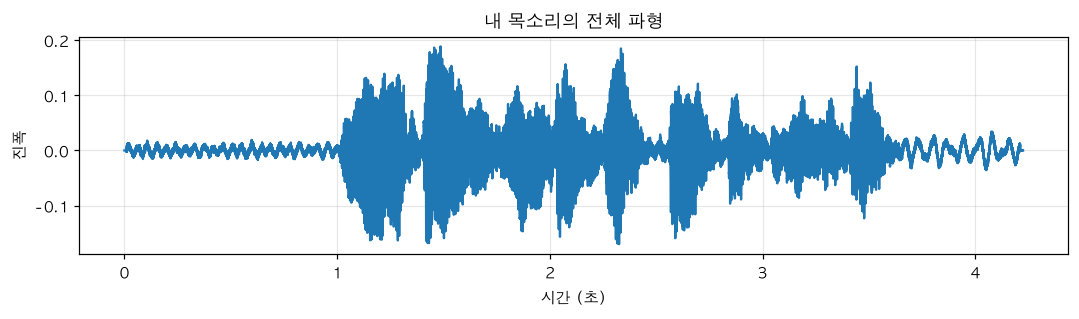

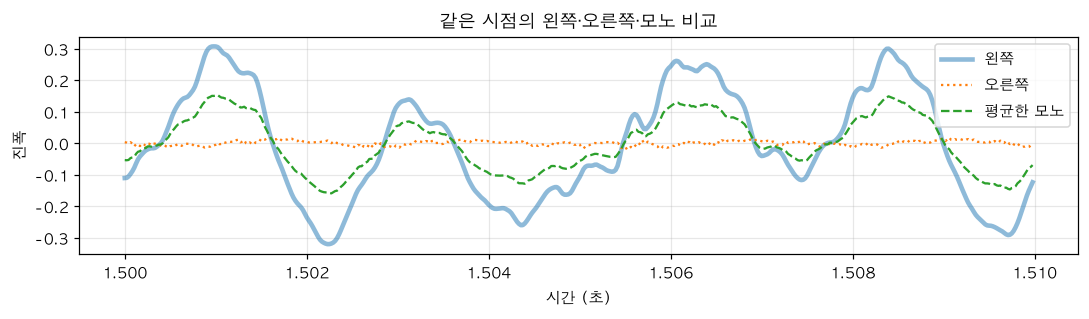


왼쪽 채널
오른쪽 채널
평균한 모노


In [78]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Audio, display

VOICE_PATH = DATA_DIR / "drafts" / "my_voice(강사님).wav"

# 1. 음성 파일 읽기
# read_pcm16()이 실수 변환과 정규화를 수행하므로
# 여기서 다시 32768로 나누지 않습니다.
# 첫 실행은 원본 녹음, 두 번째 실행은 아래 줄을 VOICE_STEREO_PATH로 변경합니다.
channel_path = VOICE_PATH
my_sr, my_stereo = read_pcm16(channel_path)

# 이번 실습에서는 좌우 채널이 있는 스테레오 파일을 사용합니다.
if my_stereo.ndim != 2 or my_stereo.shape[1] != 2:
    raise ValueError("이번 실습에는 스테레오(2채널) 파일을 사용하세요.")

print("파일:", channel_path.name)
print("좌우 값이 모두 같은가?:", np.array_equal(my_stereo[:, 0], my_stereo[:, 1]))
print("샘플링 레이트:", my_sr, "Hz")
print("스테레오 배열 모양:", my_stereo.shape)
print("채널 수:", my_stereo.shape[1])

# 행 개수는 채널 하나에 저장된 샘플 수입니다.
my_duration = my_stereo.shape[0] / my_sr
print("변환 전 길이:", my_duration, "초")


# 2. 왼쪽·오른쪽 채널 분리
# :은 모든 행을 선택한다는 뜻입니다.
my_left = my_stereo[:, 0]     # 첫 번째 열: 왼쪽 채널
my_right = my_stereo[:, 1]    # 두 번째 열: 오른쪽 채널

print("\n왼쪽 배열 모양:", my_left.shape)
print("오른쪽 배열 모양:", my_right.shape)


# 3. 좌우 채널을 평균하여 모노로 변환
# 각 행에서 (왼쪽 값 + 오른쪽 값) / 2를 계산합니다.
# 같은 시점의 값 두 개가 하나로 합쳐집니다.
my_mono = my_stereo.mean(axis=1)

print("\n모노 배열 모양:", my_mono.shape)
print("변환 후 길이:", len(my_mono) / my_sr, "초")
print("변환 전후 길이가 같은가?:",
      my_stereo.shape[0] == len(my_mono))


# 4. 1.5초 지점부터 연속된 샘플 6개 비교
check_time = 1.5
start = int(check_time * my_sr)

print(f"\n{check_time}초 지점의 샘플 비교")

if start >= len(my_mono):
    print("파일이 짧습니다. check_time을 더 작은 값으로 바꾸세요.")
else:
    # 파일 끝을 넘지 않도록 출력 범위를 제한합니다.
    end = min(start + 6, len(my_mono))

    for index in range(start, end):
        print(
            f"번호 {index}"
            f" / 왼쪽 {my_left[index]:.5f}"
            f" / 오른쪽 {my_right[index]:.5f}"
            f" / 모노 {my_mono[index]:.5f}"
        )

    # 두 채널을 더하고 2로 나눈 결과와 비교합니다.
    # 실수 계산이므로 아주 작은 오차를 허용하는 allclose()를 사용합니다.
    expected = (my_left[start:end] + my_right[start:end]) / 2
    print("모노 값이 좌우 평균과 같은가?:",
          np.allclose(my_mono[start:end], expected))


# 5-1. 모노 음성의 전체 파형
# 샘플 번호를 SR로 나누면 각 샘플의 시간(초)이 됩니다.
my_time = np.arange(len(my_mono)) / my_sr

plt.figure(figsize=(10, 3))
plt.plot(my_time, my_mono)
plt.xlabel("시간 (초)")
plt.ylabel("진폭")
plt.title("내 목소리의 전체 파형")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 5-2. 말하는 구간 중 0.01초를 확대하여 세 파형 비교
# 위 전체 파형을 보고 소리가 있는 시간으로 수정하세요.
zoom_start = 1.5
zoom_end = zoom_start + 0.01

if not (0 <= zoom_start < zoom_end <= my_duration):
    print("확대할 시작과 끝 시간을 파일 길이 안으로 지정하세요.")
else:
    begin = int(zoom_start * my_sr)
    end = int(zoom_end * my_sr)

    # 원본 파일 기준의 시간(초)을 사용합니다.
    zoom_time = np.arange(begin, end) / my_sr

    plt.figure(figsize=(10, 3))
    plt.plot(zoom_time, my_left[begin:end],
             label="왼쪽", linewidth=3, alpha=0.5)
    plt.plot(zoom_time, my_right[begin:end],
             label="오른쪽", linestyle=":")
    plt.plot(zoom_time, my_mono[begin:end],
             label="평균한 모노", linestyle="--")

    plt.xlabel("시간 (초)")
    plt.ylabel("진폭")
    plt.title("같은 시점의 왼쪽·오른쪽·모노 비교")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
# 6. 각각 재생하여 소리 비교
# 원래 SR로 재생하여 녹음 길이와 음의 높이를 유지합니다.
# normalize=False로 자동 크기 보정을 끕니다.
print("\n왼쪽 채널")
# display(Audio(my_left, rate=my_sr, normalize=False))

print("오른쪽 채널")
# display(Audio(my_right, rate=my_sr, normalize=False))

print("평균한 모노")
# display(Audio(my_mono, rate=my_sr, normalize=False))

#### 강사님 목소리 녹음 파일 변형?

파일: my_voice_stereo_practice.wav
좌우 값이 모두 같은가?: False
샘플링 레이트: 48000 Hz
스테레오 배열 모양: (197280, 2)
채널 수: 2
변환 전 길이: 4.11 초

왼쪽 배열 모양: (197280,)
오른쪽 배열 모양: (197280,)

모노 배열 모양: (197280,)
변환 후 길이: 4.11 초
변환 전후 길이가 같은가?: True

1.5초 지점의 샘플 비교
번호 72000 / 왼쪽 -0.01917 / 오른쪽 -0.00958 / 모노 -0.01437
번호 72001 / 왼쪽 -0.02002 / 오른쪽 -0.01001 / 모노 -0.01501
번호 72002 / 왼쪽 -0.02078 / 오른쪽 -0.01038 / 모노 -0.01558
번호 72003 / 왼쪽 -0.02130 / 오른쪽 -0.01065 / 모노 -0.01598
번호 72004 / 왼쪽 -0.02170 / 오른쪽 -0.01086 / 모노 -0.01628
번호 72005 / 왼쪽 -0.02191 / 오른쪽 -0.01096 / 모노 -0.01643
모노 값이 좌우 평균과 같은가?: True


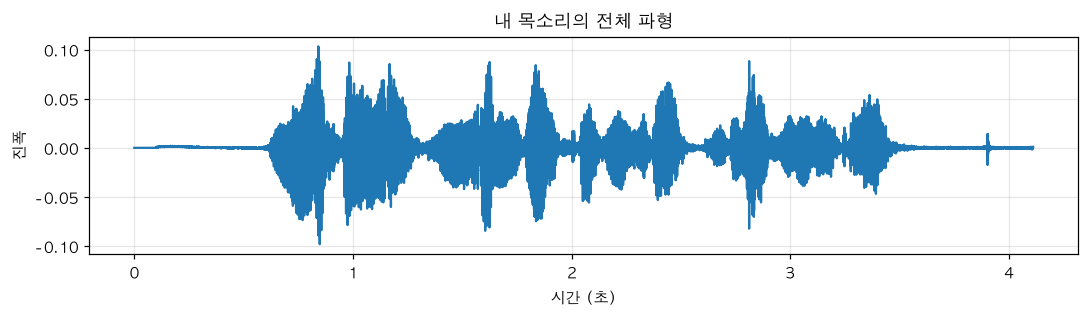

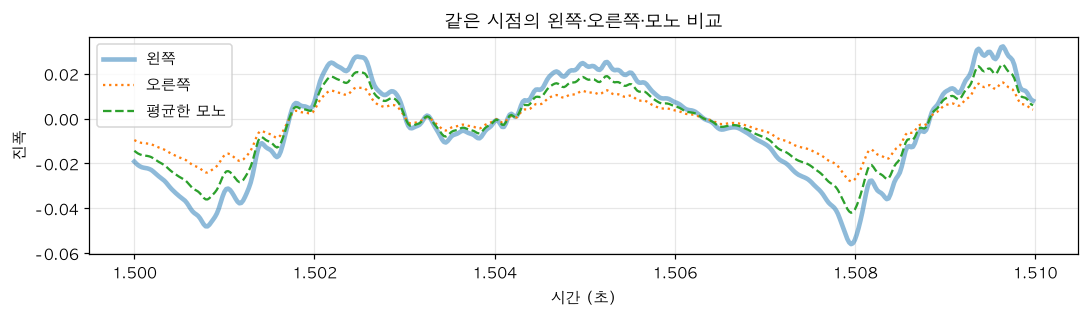


왼쪽 채널
오른쪽 채널
평균한 모노


In [79]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Audio, display

VOICE_STEREO_PATH = DATA_DIR / "my_voice_stereo_practice.wav"

# 1. 음성 파일 읽기
# read_pcm16()이 실수 변환과 정규화를 수행하므로
# 여기서 다시 32768로 나누지 않습니다.
# 첫 실행은 원본 녹음, 두 번째 실행은 아래 줄을 VOICE_STEREO_PATH로 변경합니다.

channel_path = VOICE_STEREO_PATH
my_sr, my_stereo = read_pcm16(channel_path)

# 이번 실습에서는 좌우 채널이 있는 스테레오 파일을 사용합니다.
if my_stereo.ndim != 2 or my_stereo.shape[1] != 2:
    raise ValueError("이번 실습에는 스테레오(2채널) 파일을 사용하세요.")

print("파일:", channel_path.name)
print("좌우 값이 모두 같은가?:", np.array_equal(my_stereo[:, 0], my_stereo[:, 1]))
print("샘플링 레이트:", my_sr, "Hz")
print("스테레오 배열 모양:", my_stereo.shape)
print("채널 수:", my_stereo.shape[1])

# 행 개수는 채널 하나에 저장된 샘플 수입니다.
my_duration = my_stereo.shape[0] / my_sr
print("변환 전 길이:", my_duration, "초")


# 2. 왼쪽·오른쪽 채널 분리
# :은 모든 행을 선택한다는 뜻입니다.
my_left = my_stereo[:, 0]     # 첫 번째 열: 왼쪽 채널
my_right = my_stereo[:, 1]    # 두 번째 열: 오른쪽 채널

print("\n왼쪽 배열 모양:", my_left.shape)
print("오른쪽 배열 모양:", my_right.shape)


# 3. 좌우 채널을 평균하여 모노로 변환
# 각 행에서 (왼쪽 값 + 오른쪽 값) / 2를 계산합니다.
# 같은 시점의 값 두 개가 하나로 합쳐집니다.
my_mono = my_stereo.mean(axis=1)

print("\n모노 배열 모양:", my_mono.shape)
print("변환 후 길이:", len(my_mono) / my_sr, "초")
print("변환 전후 길이가 같은가?:",
      my_stereo.shape[0] == len(my_mono))


# 4. 1.5초 지점부터 연속된 샘플 6개 비교
check_time = 1.5
start = int(check_time * my_sr)

print(f"\n{check_time}초 지점의 샘플 비교")

if start >= len(my_mono):
    print("파일이 짧습니다. check_time을 더 작은 값으로 바꾸세요.")
else:
    # 파일 끝을 넘지 않도록 출력 범위를 제한합니다.
    end = min(start + 6, len(my_mono))

    for index in range(start, end):
        print(
            f"번호 {index}"
            f" / 왼쪽 {my_left[index]:.5f}"
            f" / 오른쪽 {my_right[index]:.5f}"
            f" / 모노 {my_mono[index]:.5f}"
        )

    # 두 채널을 더하고 2로 나눈 결과와 비교합니다.
    # 실수 계산이므로 아주 작은 오차를 허용하는 allclose()를 사용합니다.
    expected = (my_left[start:end] + my_right[start:end]) / 2
    print("모노 값이 좌우 평균과 같은가?:",
          np.allclose(my_mono[start:end], expected))


# 5-1. 모노 음성의 전체 파형
# 샘플 번호를 SR로 나누면 각 샘플의 시간(초)이 됩니다.
my_time = np.arange(len(my_mono)) / my_sr

plt.figure(figsize=(10, 3))
plt.plot(my_time, my_mono)
plt.xlabel("시간 (초)")
plt.ylabel("진폭")
plt.title("내 목소리의 전체 파형")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 5-2. 말하는 구간 중 0.01초를 확대하여 세 파형 비교
# 위 전체 파형을 보고 소리가 있는 시간으로 수정하세요.
zoom_start = 1.5
zoom_end = zoom_start + 0.01

if not (0 <= zoom_start < zoom_end <= my_duration):
    print("확대할 시작과 끝 시간을 파일 길이 안으로 지정하세요.")
else:
    begin = int(zoom_start * my_sr)
    end = int(zoom_end * my_sr)

    # 원본 파일 기준의 시간(초)을 사용합니다.
    zoom_time = np.arange(begin, end) / my_sr

    plt.figure(figsize=(10, 3))
    plt.plot(zoom_time, my_left[begin:end],
             label="왼쪽", linewidth=3, alpha=0.5)
    plt.plot(zoom_time, my_right[begin:end],
             label="오른쪽", linestyle=":")
    plt.plot(zoom_time, my_mono[begin:end],
             label="평균한 모노", linestyle="--")

    plt.xlabel("시간 (초)")
    plt.ylabel("진폭")
    plt.title("같은 시점의 왼쪽·오른쪽·모노 비교")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
# 6. 각각 재생하여 소리 비교
# 원래 SR로 재생하여 녹음 길이와 음의 높이를 유지합니다.
# normalize=False로 자동 크기 보정을 끕니다.
print("\n왼쪽 채널")
# display(Audio(my_left, rate=my_sr, normalize=False))

print("오른쪽 채널")
# display(Audio(my_right, rate=my_sr, normalize=False))

print("평균한 모노")
# display(Audio(my_mono, rate=my_sr, normalize=False))

### 2교시 QnA

1. 길이가 유지되는 이유
2. 왼쪽 선택과 평균의 차이
3. 좌우가 같으면
4. 0.4와 -0.4의 평균
5. 잡음 제거 여부

# 2026-10-21(수) 수업 리뷰 — 02 노트북 (실행 결과 검토)

수치는 `data/`와 `data/drafts/`의 파일을 직접 읽어 계산한 값입니다. 추정은 (추정)으로 표시했습니다.

### 1. 총평
- **잘한 것:** 같은 실습을 **여러 파일(QuickTime, iPhone, 온라인 녹음, 강사님 파일)로 돌려 보고** 결과가 왜 다른지 스스로 묻고 있습니다. "모노 변환 결과가 왼쪽과 똑같아 보인다"는 관찰이 정확했습니다. `clean vs noisy`에서 `figsize`를 바꿔 보고 RMS 값을 직접 추가로 찍어 본 것도 좋은 습관입니다.
- **의미 있는 실험이 안 된 파일을 `drafts/`에 모은 판단도 맞습니다.** 아래 표가 그 이유입니다. 다만 실험 결과가 "왜 안 됐는지"가 이번 수업의 가장 큰 배움입니다(2번).

### 2. 녹음 파일 비교 (직접 계산)
| 파일 | SR | 채널 | 길이 | 최대 크기 | 좌우 관계 | 모노 변환 실습에 쓸 만한가 |
|---|---|---|---|---|---|---|
| QuickTime → `afconvert` (`drafts/my_voice(by mac).wav`) | 44100 | 2 (파일 형식) | 8.75초 | 0.054 | **`L == R` 완전히 같음** (상관계수 1.0) | **아니오.** 평균해도 왼쪽과 똑같습니다 |
| iPhone (`my_recording(iphone).m4a`) | 48000 | **1** (`afinfo`로 확인) | 9.13초 | — | 채널이 하나 | **아니오.** 44번 셀의 "스테레오 파일을 사용하세요" 검사(`ValueError`)에서 멈추는 것이 정상입니다 |
| 온라인 녹음 (현재 `data/my_voice.wav`) | 44100 | 2 | 7.96초 | **0.013** | 거의 비슷하지만 다름 (상관계수 0.94, 최대 차이 161/32768) | **가능.** 단, 차이가 아주 작고 소리도 매우 작습니다 |
| 강사님 녹음 (`drafts/my_voice(강사님).wav`) | 48000 | 2 | 4.22초 | 0.378 | **왼쪽이 오른쪽보다 약 17배 큼** (RMS 0.0715 vs 0.0043) | **가능.** 좌우가 뚜렷하게 다릅니다 |
| 강사님 연습 파일 (`my_voice_stereo_practice.wav`) | 48000 | 2 | 4.11초 | 0.138 | **오른쪽 = 왼쪽 × 0.5** (잔차 RMS 0.00001) | **가능.** 평균 결과가 한 눈에 계산되는 연습용입니다 |

### 3. 핵심 질문에 대한 답
**Q. QuickTime으로 녹음하면 스테레오인데 모노처럼 "변형"되어 저장되나?**
- 확인된 사실: 파일 형식은 `2 ch`(`afinfo`)인데 두 채널의 값이 **한 샘플도 다르지 않습니다**(`np.array_equal` True). 47번 셀의 3.5초 확대 그림에서 왼쪽·오른쪽·평균 세 선이 겹쳐 하나로 보인 이유입니다(캡처해 두신 QuickTime 그림).
- 해석(추정): 마이크는 하나인데 같은 소리를 두 채널에 복사해 2채널 형식으로 저장한 것으로 보입니다. 소리가 "변형"된 것이라기보다 **채널 수와 내용이 다른 것**입니다. 채널 수(`shape[1]`)만 보고 "진짜 스테레오"라고 판단하면 안 되고, `np.array_equal(왼쪽, 오른쪽)`으로 확인해야 합니다.
- 이 경우 `mean(axis=1)`이 만든 모노 = 왼쪽과 같아서, "평균으로 모노를 만든다"는 이번 실습의 요점이 드러나지 않습니다.

**Q. iPhone은 모노로 저장되나?**
- 이 녹음 파일은 `1 ch, 48000 Hz, 9.13초`(`afinfo`로 확인)입니다. 강사님 변환 코드에는 `-ac`(채널 수 변경) 옵션이 없고, FFmpeg는 이 옵션이 없으면 원본 채널 수를 유지합니다(일반 동작, 직접 실행은 못 함). 그래서 WAV도 모노(`(439232,)`, 이전에 붙여 주신 결과)가 나온 것으로 보입니다. **이 한 파일을 근거로 "iPhone은 항상 모노"라고 일반화하지는 마세요.**

**Q. 온라인 녹음은 왜 좌우가 조금 다른가?**
- 값이 다르다는 것(상관 0.94)은 확인했습니다. 왜 다른지(스테레오 마이크인지, 사이트의 처리 때문인지)는 알 수 없습니다. 모르는 것으로 두세요.
- 소리가 작습니다(최대 0.013 = 전체 범위의 1.3%). 그래서 두 번째 스크린샷의 진폭이 ±0.005 정도입니다. 나중에 정규화(볼륨 키우기)가 필요한 이유의 실제 예입니다.

**Q. 강사님 파일에서 모노 변환을 하면 무슨 일이 생기나?**
- 왼쪽 RMS 0.0715, 오른쪽 0.0043이라서 평균한 모노의 RMS가 0.0355입니다. **왼쪽의 약 절반**입니다. 한쪽 채널이 훨씬 작으면 평균은 큰 채널의 소리를 절반으로 줄입니다. 평균 모노가 "손실 없는 변환"은 아닙니다.
- 좌우 상관계수가 -0.14(시간차 없이 비교)인데, 한쪽을 약 27샘플(0.56 ms) 밀어서 비교하면 0.33으로 올라갑니다. 좌우 소리가 **약간 어긋난 시간**에 도착한다는 뜻으로 두 마이크 위치 차이일 수 있습니다(추정).
- 연습 파일은 `오른쪽 = 0.5 × 왼쪽`이라서 평균 = `0.75 × 왼쪽`입니다(출력 `-0.01917`, `-0.00958` → `-0.01437`로 확인).

### 4. 노트북에서 고치면 좋은 곳
1. **파일 이름과 출력이 어긋난 셀(16/17번, 23/24번):** 16번 셀 제목은 "mac 터미널로 변환한 파일"인데 출력은 `(351036, 2)`, **7.96초**입니다. 이 값은 **온라인 녹음**의 값입니다. 17번 셀 제목은 "강사님 코드로 변환한 파일"인데 출력 `(385984, 2)`, **8.75초**는 **QuickTime → `afconvert`** 파일의 값입니다. 실행한 시점의 `my_voice.wav`가 달랐던 것으로 보입니다(추정). 제목을 지금 파일 기준으로 다시 붙이거나, 파일 이름을 출력하게(`print(VOICE_PATH.name)`) 하면 헷갈리지 않습니다.
2. **`VOICE_PATH` 덮어쓰기:** 50번 셀이 `VOICE_PATH = DATA_DIR / "drafts" / "my_voice(강사님).wav"`로 바꿔서, 이후 `VOICE_PATH`를 쓰는 셀을 다시 실행하면 내 목소리가 아니라 **강사님 파일**을 읽습니다. 다른 이름(`instructor_path`)을 쓰는 편이 안전합니다.
3. **2번 셀의 `VOICE_KEY_MAC_PATH`:** 이름이 `BY` → `KEY` 오타로 보이고, 경로 `data/my_voice(by mac).wav`에 파일이 **없습니다**(지금은 `data/drafts/` 안). 이 경로로 44번 셀을 돌리면 `FileNotFoundError`가 납니다.
4. **14번 셀("나의 시도")의 `AttributeError`가 그대로 남아 있습니다.** `voice1_sr.shape`와 `sample_path`를 `voice1_path`로 고쳐야 합니다(앞 검토 코멘트 참고).
5. **39번 셀 출력 이름:** `440Hz 구간 RMS`라고 찍히지만 1.0~1.5초 구간은 **880 Hz**입니다(FFT로 확인: 피크 880.0 Hz).
6. **파일 크기:** 이 노트북이 약 7.6 MB(01은 약 1.7 MB)입니다. 36번 셀 `figsize=(50, 5)`가 5500×550 픽셀 그림을 만들고, `Audio` 재생기마다 소리 데이터가 통째로 들어가기 때문입니다. 공개 저장소에 올릴 때는 **출력 지우기(Clear All Outputs)** 후 커밋하는 편이 좋습니다.

### 5. RMS가 뭔지 (39번 셀 질문)
- **RMS = 제곱 → 평균 → 제곱근** (`rms()` 함수 그대로). "소리의 평균적인 세기"입니다. 음수·양수가 서로 상쇄되지 않도록 먼저 제곱합니다.
- 사인파는 **진폭 A이면 RMS = A/√2** 입니다. 진폭 0.3이면 `0.3 / 1.4142 = 0.2121` → 출력 `0.2121`과 일치합니다(직접 계산).
- **주파수가 바뀌어도 RMS는 같습니다.** 440 Hz든 880 Hz든 진폭이 같으면 세기가 같기 때문입니다. 질문의 관찰(주파수가 높아도 RMS가 비슷)이 맞습니다.
- 잡음 합성음의 무음 구간 RMS `0.0200`은 **잡음의 세기** 자체입니다(추정: 잡음 세기가 0.02로 설정됨, 노트북에 생성 코드는 없음). 소리+잡음 구간 RMS는 `√(0.2121² + 0.02²) = 0.2131`로 예상되고 출력은 `0.2133`입니다. 세기는 제곱해서 더해지므로, 잡음이 작으면 총 세기는 거의 안 변합니다.

### 6. 커밋 전 확인 (★)
- `017_sound/data/`(내 목소리 `my_voice*.wav`, `drafts/`의 녹음과 m4a)와 `017_sound/results/`(스크린샷)가 **`.gitignore`에 없습니다.** 지금 `git add`를 하면 공개 저장소에 올라갑니다.
- 02 노트북의 2번 셀 출력에 내 컴퓨터 경로(`/Users/…`)가 들어 있습니다.

---


# 2026.10.22(목) 19h~

### 잡음을 더한 합성음 파일 만들기

In [82]:
import numpy as np
from scipy.io import wavfile
from pathlib import Path
from IPython.display import Audio, display

# 1. 기본 조건
SR = 16000
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)


# 2. 사인파를 만드는 함수
def make_tone(frequency, duration, amplitude=0.3, sr=SR):
    time = np.arange(int(round(sr * duration))) / sr
    return amplitude * np.sin(2 * np.pi * frequency * time)


# 3. 잡음이 없는 2초짜리 합성음 생성
# 무음 → 440 Hz → 무음 → 880 Hz → 무음
sequence = np.concatenate([
    np.zeros(int(SR * 0.25)),                  # 0.00~0.25초: 무음
    make_tone(440, duration=0.5),              # 0.25~0.75초: 440 Hz
    np.zeros(int(SR * 0.25)),                  # 0.75~1.00초: 무음
    make_tone(880, duration=0.5),              # 1.00~1.50초: 880 Hz
    np.zeros(int(SR * 0.5))                    # 1.50~2.00초: 무음
])


# 4. 합성음과 같은 개수의 잡음 샘플 생성
# 시드를 고정하면 다시 실행해도 같은 잡음이 만들어집니다.
# default_rng(42): 난수 생성기를 만듭니다. 42는 '시작 번호(시드)'이고 숫자 자체에 특별한 뜻은 없습니다.
#   같은 시드 → 항상 같은 숫자 순서가 나옵니다(직접 확인). 시드를 7로 바꾸면 다른 잡음이 나옵니다.
#   이 생성기에서 숫자를 뽑을 때마다 순서가 이어지므로, 아래 normal()은 이 줄 다음 첫 숫자부터 뽑습니다.
rng = np.random.default_rng(42)

# 평균 0, 표준편차 0.02인 정규분포 잡음입니다.
# 0.02는 최대값이 아니라 잡음의 전반적인 크기를 정하는 값입니다.
# 정규분포(종 모양): 0 근처 값이 가장 많이 나오고, 멀어질수록 드물어집니다.
#   표준편차 σ=0.02이면 약 68%의 값이 ±0.02 안, 약 95%가 ±0.04 안, 약 99.7%가 ±0.06 안에 들어갑니다.
#   (이 코드로 32000개를 뽑아 세어 보니 67.9% / 95.4% / 99.7%였습니다)
#   하지만 상한은 없어서, 0.02보다 큰 값도 나옵니다. 실제로 가장 큰 값은 약 0.088(σ의 4배 이상)이었습니다.
noise_level = 0.02 # 0.1 = 훨씬 더 심한 noises를 만듦
#   noise_level을 0.1로 바꾸면 같은 시드에서 모든 잡음 값이 정확히 5배(0.1 ÷ 0.02)가 됩니다.
noise = rng.normal(
    loc=0.0,              # loc(location): 평균. 0이면 +쪽과 -쪽이 같은 정도로 나와 파형의 기준선이 안 움직입니다.
    scale=noise_level,    # scale: 표준편차. 잡음이 평균에서 퍼지는 정도 = 잡음의 크기(RMS가 약 0.02가 되는 이유)
    size=len(sequence)    # size: 뽑을 개수. 합성음 샘플 수(여기서는 32000개)와 같아야 아래에서 1:1로 더할 수 있습니다.
)

# 같은 시각의 합성음 값과 잡음 값을 더합니다.
# 원래 무음이었던 구간에도 잡음이 들어갑니다.
# sequence[n] + noise[n]을 샘플 번호 n마다 계산합니다(NumPy 배열끼리 더하면 같은 번호끼리 더해집니다).
# 샘플마다 서로 상관없이 따로 뽑은 값이라 '치지직' 하는 배경 잡음처럼 들립니다.
noisy = sequence + noise


# 5. 계산용 실수를 PCM16 정수로 바꿉니다.
# 정수 눈금으로 확대 → 반올림 → 저장 범위 제한 → int16 변환
# clip은 범위를 넘는 값을 제한하며, 잡음을 제거하는 기능은 아닙니다.
noisy_pcm16 = np.clip(
    np.rint(noisy * 32768),
    -32768,
    32767
).astype(np.int16)


# 6. WAV 파일로 저장합니다.
# 같은 이름의 파일이 있으면 이번 결과로 덮어씁니다.
output_path = DATA_DIR / "tone_sequence_noisy_16k_mono_new.wav"
wavfile.write(output_path, SR, noisy_pcm16)


# 7. 저장한 파일을 다시 읽어 확인합니다.
check_sr, check_raw = wavfile.read(output_path)

print("저장 위치:", output_path.resolve())
print("SR:", check_sr, "Hz")
print("배열 모양:", check_raw.shape)
print("자료형:", check_raw.dtype)
print("길이:", len(check_raw) / check_sr, "초")


# 8. 원래 합성음과 실제 저장한 잡음 합성음을 비교해서 듣습니다.
print("잡음이 없는 합성음")
display(Audio(sequence, rate=SR, normalize=False))

print("잡음을 더해 저장한 합성음")
check_audio = check_raw.astype(np.float32) / 32768.0
display(Audio(check_audio, rate=check_sr, normalize=False))

SR: 16000 Hz
배열 모양: (32000,)
자료형: int16
길이: 2.0 초
잡음이 없는 합성음


잡음을 더해 저장한 합성음


### Q. `default_rng(42)`, `normal(loc, scale, size)`, `noise_level`은 정확히 무엇인가?

수치는 이 셀의 코드를 그대로 실행해서 확인했습니다. 강사님 의도는 확인하지 못한 부분(추정)을 따로 표시했습니다.

#### 1. 이 코드가 하는 일 (한 줄)
**"소리 샘플 32000개 각각에 더할, 평균 0 · 표준편차 0.02인 무작위 숫자 32000개"를 만들어서 합성음에 더하는 것**입니다. 결과가 `noisy`(잡음 낀 소리)입니다.

#### 2. 줄별 설명
| 코드 | 의미 | 직접 확인한 값 |
|---|---|---|
| `np.random.default_rng(42)` | 난수를 만드는 기계를 켭니다. `42`는 시작 번호(시드) | 같은 시드로 두 번 만들면 값이 **완전히 같음**(True), 시드를 7로 바꾸면 **다름**(False) |
| `rng.normal(loc=0.0, scale=0.02, size=32000)` | 정규분포를 따르는 숫자 32000개를 뽑습니다 | 평균 `0.00017`, 표준편차 `0.02007` |
| `loc` | 평균(분포의 중심) | 0이면 위·아래로 대칭 |
| `scale` | 표준편차(퍼지는 정도) | 클수록 잡음이 큼 |
| `size` | 뽑을 개수 | `len(sequence) = 32000`(2초 × 16000) |
| `noisy = sequence + noise` | 같은 번호끼리 더함 | 무음 구간(처음 4000개)의 표준편차 `0.01999` ≈ 잡음 크기 |

#### 3. 시드를 고정하는 이유
- 시드를 고정하면 **실행할 때마다 같은 잡음**이 나옵니다. 그래서 결과(RMS 등)를 다시 실행해도 같은 값으로 비교할 수 있고, 다른 사람과 결과를 맞출 수 있습니다.
- 시드의 숫자 값(42)에는 의미가 없습니다. 관례로 많이 쓰는 숫자입니다(일반 지식).
- 시드를 빼면(`default_rng()`) 실행할 때마다 잡음이 달라집니다.

#### 4. "표준편차 0.02"는 어느 정도의 크기인가
- `0.02`는 **최대값이 아닙니다.** 정규분포는 큰 값도 가끔 나옵니다. 32000개를 뽑아 세어 보니:

| 범위 | 이론값 | 이 코드 결과 |
|---|---|---|
| ±0.02 (1σ) 안 | 약 68% | 67.9% |
| ±0.04 (2σ) 안 | 약 95% | 95.4% |
| ±0.06 (3σ) 안 | 약 99.7% | 99.7% |
| 가장 큰 값 | (상한 없음) | 최소 `-0.088`, 최대 `+0.083` |

- 소리 단위로 보면 `0.02 × 32768 ≈ 655`입니다(16비트 정수 눈금에서 수백). 합성음 진폭 0.3과 비교하면 작지만 무음 구간의 배경으로는 뚜렷합니다. 앞 셀의 RMS `0.0200`이 이 값입니다.
- `noise_level = 0.1`로 바꾸면 같은 시드에서 **모든 값이 정확히 5배**가 됩니다(0.1 ÷ 0.02). 표준편차 0.1은 가장 큰 값이 약 0.44까지 나와서, 진폭 0.3인 소리와 비슷한 크기의 잡음이 됩니다. 확실히 더 심한 잡음이 들립니다.

#### 5. 이 잡음의 성질
- 샘플마다 **서로 상관없이** 따로 뽑습니다. 그래서 소리의 높낮이가 없는 '치지직' 소리(백색잡음)입니다. 이 이름은 일반 지식이며 노트북에서 확인한 것은 아닙니다.
- `noisy = sequence + noise`로 **원래 소리를 지우는 것이 아니라 얹는 것**입니다. `noisy`의 값 범위는 약 -0.39 ~ +0.36으로 ±1 안이라서 `np.clip`이 실제로 값을 자르는 일은 일어나지 않습니다.
- 5번 단계의 반올림 오차는 최대 약 `0.0000153`(= 1/65536)로 잡음 0.02보다 훨씬 작습니다.

#### 6. 알아 두면 좋은 점 (★)
- **이 코드로 만든 `tone_sequence_noisy_16k_mono_new.wav`는 강사님이 주신 `tone_sequence_noisy_16k_mono.wav`와 같지 않습니다.** 두 파일의 정수 값이 최대 3903까지 다릅니다(직접 비교). 강사님 파일은 다른 시드나 다른 설정으로 만들었을 것입니다(추정). 그래도 무음 구간 RMS가 둘 다 약 `0.02`로 같은 수준이라 실습 결과는 비슷하게 나옵니다.
- 이 셀의 출력 "저장 위치"에 내 컴퓨터 전체 경로(`/Users/…`)가 찍혀 있습니다. 커밋 전에 이 셀의 출력을 지우세요.


## 3교시. 재생 sampling rate 변경 및 올바른 resampling

### 1. 원리 이해하기

### 왜 샘플링 레이트는 소리 주파수의 2배보다 커야 할까요? `SR-주파수 관계`

#### 1. 소리의 주파수와 샘플링 레이트의 차이

먼저 두 개념을 구분해야 합니다.

- **소리의 주파수(Hz)**: 소리가 1초 동안 몇 번 진동하는가?
- **샘플링 레이트(SR)**: 소리의 진폭을 1초 동안 몇 번 측정하는가?

예를 들어 1,000Hz 소리는 1초 동안 1,000번 진동합니다.

따라서 한 번 진동하는 데 걸리는 시간은 다음과 같습니다.

**1 ÷ 1,000 = 0.001초 = 1ms**

즉, 1ms마다 같은 진동이 반복됩니다.

#### 2. 진동 한 번에 한 번만 측정하면 어떻게 될까요?

1,000Hz 사인파를 1,000Hz로 샘플링한다고 가정하겠습니다.

- 소리는 1ms마다 한 번 진동합니다.
- 샘플링도 1ms마다 한 번 수행합니다.

다음 그림에서 `●`는 실제로 측정한 위치입니다.

**실제 소리는 계속 진동하지만, 측정 위치는 매번 같습니다.**

![Screenshot 2026-10-22 at 19.47.31.png]

소리는 실제로 위아래로 진동하고 있지만, 컴퓨터에 저장된 값은 모두 0입니다.

컴퓨터는 이 숫자만 보고 소리가 진동했는지, 진동하지 않았는지 구분할 수 없습니다.

**즉, 진동 한 번에 한 번만 측정하면 실제 진동을 놓칠 수 있습니다.**

#### 3. 그러면 진동 한 번에 두 번 측정하면 될까요?

한 번보다 두 번 측정하면 더 많은 정보를 얻을 수 있습니다.

하지만 정확히 두 번만 측정하는 경우에도 문제가 발생할 수 있습니다.

예를 들어 사인파가 0을 지나는 위치와 반 주기 뒤의 0을 지나는 위치만 측정하면, 결과는 여전히 모두 0입니다.

따라서 **진동 한 번에 정확히 2개의 샘플이 있다고 해서 항상 원래 신호를 복원할 수 있는 것은 아닙니다.**

이 문제를 설명하는 것이 **나이퀴스트 샘플링 정리(Nyquist Sampling Theorem)** 입니다.

일정한 조건에서 원래 신호를 복원하려면 다음 관계를 만족해야 합니다.

**샘플링 레이트 > 2 × 신호의 최고 주파수**

이때 신호에는 최고 주파수보다 높은 성분이 없어야 하며, 복원에도 적절한 수학적 처리가 필요합니다.

#### 4. 샘플링 레이트에 따른 측정 횟수 비교

1,000Hz 사인파를 서로 다른 샘플링 레이트로 측정한다고 가정하겠습니다.

| 샘플링 레이트 | 진동 한 번당 샘플 수 | 결과 |
|---|---:|---|
| 1,000Hz | 1개 | 원래 진동을 구분할 수 없음 |
| 2,000Hz | 2개 | 경계 조건으로 복원을 보장할 수 없음 |
| 4,000Hz | 4개 | 이상적인 조건에서 복원 가능 |
| 8,000Hz | 8개 | 더 촘촘하게 측정 |
| 48,000Hz | 48개 | 매우 촘촘하게 측정 |

샘플을 촘촘하게 측정하면 원래 신호에 대한 정보를 더 많이 얻을 수 있습니다.

다만 샘플 사이를 단순히 직선으로 연결한다고 원래 파형이 정확하게 복원되는 것은 아닙니다.

#### 5. 왜 48,000Hz의 절반인 24,000Hz일까요?

48,000Hz로 샘플링한다는 것은 1초 동안 48,000번 측정한다는 뜻입니다.

나이퀴스트 샘플링 정리에 따라 이론적인 경계 주파수를 계산하면 다음과 같습니다.

**48,000 ÷ 2 = 24,000Hz**

이 24,000Hz를 **나이퀴스트 주파수(Nyquist Frequency)** 라고 합니다.

| 샘플링 레이트 | 나이퀴스트 주파수 |
|---|---:|
| 48,000Hz | 24,000Hz |
| 24,000Hz | 12,000Hz |
| 16,000Hz | 8,000Hz |
| 8,000Hz | 4,000Hz |

나이퀴스트 주파수는 디지털 신호가 원래 주파수 성분을 올바르게 표현하고 복원할 수 있는 이론적인 경계입니다.

정확히 경계에 있는 주파수까지 무조건 복원할 수 있다는 의미는 아니며, 일반적으로 그보다 낮은 주파수 성분을 대상으로 합니다.

#### 6. 리샘플링과의 관계

48,000Hz로 녹음한 음성을 16,000Hz로 리샘플링하면 나이퀴스트 주파수는 다음과 같이 달라집니다.

- 원본 48,000Hz → 나이퀴스트 주파수 24,000Hz
- 변환 후 16,000Hz → 나이퀴스트 주파수 8,000Hz

변환된 음성은 8,000Hz 이상의 주파수 성분을 올바르게 표현할 수 없습니다.

따라서 리샘플링 과정에서는 이러한 높은 주파수 성분을 필터로 줄인 다음 새로운 샘플을 계산합니다.

이 과정은 원래 음성의 재생 시간과 음의 높이를 유지하면서 새로운 샘플링 레이트에 맞게 데이터를 변환하기 위한 것입니다.

#### 핵심 정리

> 소리가 진동하는 속도에 비해 너무 드물게 측정하면, 서로 다른 소리가 똑같은 숫자로 기록될 수 있습니다.
>
> 이러한 문제를 피하고 원래 신호를 복원하려면, 신호의 최고 주파수보다 2배 넘게 빠르게 샘플링해야 합니다.
>
> 따라서 48,000Hz로 샘플링한 신호의 나이퀴스트 주파수는 24,000Hz입니다.
>
> **샘플링 레이트는 측정 속도이고, 나이퀴스트 주파수는 올바르게 표현할 수 있는 주파수의 이론적인 경계입니다.**

### 2. 첫번째 방법 = 재생 sampling rate만 변경

# 2026.10.22(목) 20h~

(처음 10분 정도 책상에서 자느라 수업 못 들음)

In [ ]:
# 이 셀에서 사용할 합성음을 다시 읽어 다른 실습 변수의 영향을 피합니다.
rate5, sound5 = read_pcm16(DATA_DIR / "tone_sequence_16k_mono.wav") # 이 파일의 sampling rate = 16000, 지금까지 실습에서 대부분 이 값이었음
wrong_rate5 = 8000
print("올바른 길이:", len(sound5) / rate5, "초")
display(Audio(sound5, rate=rate5, normalize=False))
# 샘플 수는 그대로인데 1초에 읽는 수가 절반이므로 길이는 두 배입니다.
print("잘못된 SR의 길이:", len(sound5) / wrong_rate5, "초")
display(Audio(sound5, rate=wrong_rate5, normalize=False))

올바른 길이: 2.0 초


잘못된 SR의 길이: 4.0 초


### 실습6. 합성음의 22,060Hz를 16,000Hz로 resampling

1. 실습 목적
   
2. 변환 과정
- 스테레오를 모노로 변환
- sampling rate를 16,000Hz로 변환
- 변환 비율 계산

3. 주요 함수의 역할
- `gcd()`
- `resample.poly()`
- `len()`

4. 결과 확인
- 변환 비율이 ~

**핵심 정리**

In [86]:
#이 코드의 목적은 22,050Hz 스테레오 소리를 16,000Hz 모노 소리로 바꾸면서, 
# 원래의 2초 길이와 음의 높이를 유지하는 것
# 음성 모델이 요구하는 입력 조건에 맞추는 기본 전처리
from scipy.signal import resample_poly

# 스테레오 합성음을 다시 읽어 평균한 모노를 준비합니다.
# source_sr: 원본의 샘플링 레이트인 22050
# stereo: 좌우 채널의 값이 들어 있는 실수 배열, stereo.shape은 (44100, 2)
source_sr, stereo = read_pcm16(DATA_DIR / "tone_sequence_22050_stereo.wav")
mono = stereo.mean(axis=1) #좌우 채널을 평균하여 모노로 변경 - 스테레오: (44100, 2) ->모노:(44100,)
target_sr = 16000 #변환 후에는 1초를 16,000개의 샘플로 표현하겠다는 뜻
# 변환 비율 = 목표 SR ÷ 원본 SR = 16000 ÷ 22050 ≈ 0.7256 : 샘플 수를 원래의 약 72.56%로 변경

# 목표 SR / 원본 SR = 16000 / 22050 = 320 / 441
# 최대공약수 50으로 나누어 같은 비율을 작은 정수로 표현합니다.
# gcd()는 최대공약수를 구하는 함수. (최대공약수는 두 수를 모두 나눌 수 있는 가장 큰 양의 정수)
common = gcd(source_sr, target_sr)
up = target_sr // common       # 320: 비율의 분자
down = source_sr // common     # 441: 비율의 분모

# 단순히 샘플을 버리는 것이 아니라 필터링과 새 값 계산을 수행합니다.
# resample_poly()는 SciPy의 scipy.signal 모듈에서 제공하는 리샘플링 함수.
# from scipy.signal import resample_poly로 가져오며, up/down 비율에 맞게 새 음성 배열을 계산합니다.
resampled = resample_poly(mono, up=up, down=down)
print("변환 비율 = up / down = ", up, "/", down)
print("변환 전 sampling rate = ", source_sr, "Hz, 샘플 갯수 = ", len(mono), "개, 음성 파일 길이 = ", len(mono)/source_sr, "초")
print("변환 후 sampling rate = ", target_sr, "Hz, 샘플 갯수 = ", len(resampled), "개, 음성 파일 길이 = ", len(resampled)/target_sr, "초")

변환 비율 = up / down =  320 / 441
변환 전 sampling rate =  22050 Hz, 샘플 갯수 =  44100 개, 음성 파일 길이 =  2.0 초
변환 후 sampling rate =  16000 Hz, 샘플 갯수 =  32000 개, 음성 파일 길이 =  2.0 초


`resample.poly()`의 개념적 처리 순서

1. 늘리기
2. 필터 처리
3. 골라내기

cf. 01 파일 내용 reminder

**resampling 전에 필터가 필요한 이유**

### Q. `resample_poly(x, up=…, down=…)`의 `up`, `down`은 뭐고, 왜 이런 숫자가 나오나?

**한 줄 답:** 네, `up`은 **분자**, `down`은 **분모**입니다. `up / down = 목표 SR ÷ 원본 SR` = **새 샘플 수 ÷ 원래 샘플 수**입니다. 이 패턴(`gcd` → `up` → `down` → `resample_poly`)은 이 노트북에서 64번·67번·72번·73번·77번·83번 셀에 반복해서 나옵니다. 수치는 모두 이 코드로 직접 계산해 확인했습니다. 내부 단계 설명(3단계)은 SciPy가 설명하는 일반적인 원리이고, 중간 배열을 꺼내 보지는 않았습니다(일반 지식).

#### 1. 먼저 문제: "눈금이 다른 두 자"
- 원본은 1초에 22050번, 목표는 1초에 16000번 잰 자료입니다. **같은 2초**를 표현하되 **눈금(샘플 간격)만 바꾸고 싶은 것**입니다.
- 새 배열의 `m`번째 샘플은 원본으로 치면 `m × 22050 ÷ 16000`번째 자리에 해당합니다.

| 새 번호 m | 0 | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|---|
| 원본에서의 위치 | 0 | **1.378** | **2.756** | **4.134** | **5.513** | **6.891** | **8.269** |

- 대부분이 **원본 샘플 사이(소수점 위치)** 에 있습니다. 원본에는 그 위치의 값이 없으니 **주변 값으로 새로 계산**해야 합니다(보간). 그래서 "샘플을 몇 개 버리면 된다"가 아닙니다.

#### 2. `up`/`down`의 직관: "임시로 아주 촘촘한 눈금을 만들었다가 골라 담기"
정수 비율 `up / down`로 쓰면 이렇게 됩니다.

```text
① 원본 샘플 사이마다 (up-1)개의 빈칸(0)을 끼워 넣음   → 샘플이 up배로 늘어남 (촘촘한 임시 눈금)
② 저역통과 필터를 적용                                  → 빈칸을 주변 값으로 부드럽게 메우고, 너무 높은 소리를 제거
③ 그 임시 눈금에서 down칸마다 하나씩만 골라 담음        → 샘플이 1/down로 줄어듦
```
- 두 SR을 모두 정수로 맞춘 **공통 눈금**이 가운데에 생깁니다. 22050 → 16000에서는 `22050 × 320 = 16000 × 441 = 7,056,000 Hz`입니다. 원본 눈금 1칸을 320개로 쪼갰다가, **441칸마다 하나** 고르면 16000 Hz 눈금이 됩니다.
- 그래서 `up`은 **"몇 배로 촘촘하게 만들까"**, `down`은 **"그중 몇 칸마다 하나씩 고를까"** 입니다. 비율 전체는 `320/441 ≈ 0.7256`이라 결과는 줄어듭니다(`up`이 있다고 늘어나는 것이 아님).
- (참고) SciPy는 실제로 중간의 큰 배열을 다 만들지 않고 계산을 아끼는 방식(다상 필터)으로 같은 결과를 냅니다. 이 설명은 "무슨 일이 일어나는가"를 이해하기 위한 그림입니다.

#### 3. `gcd`(최대공약수)로 약분하는 이유
`16000 / 22050`과 `320 / 441`은 **같은 비율**입니다(둘 다 ÷50). 약분하면 공통 눈금이 작아집니다.

| 변환 | gcd | up | down | 공통 눈금 |
|---|---|---|---|---|
| 22050 → 16000 | 50 | **320** | **441** | 7,056,000 Hz |
| 44100 → 16000 (내 녹음) | 100 | **160** | **441** | 7,056,000 Hz |
| 48000 → 16000 | 16000 | **1** | **3** | 48,000 Hz |
| 48000 → 24000 | 24000 | **1** | **2** | 48,000 Hz |
| 8000 → 16000 | 8000 | **2** | **1** | 16,000 Hz |

- 약분하지 않고 `up=16000, down=22050`을 넣어도 **결과는 같습니다**(직접 비교: `np.allclose` → True). `resample_poly`가 안에서 약분하기 때문입니다. 노트북에서 직접 `gcd`로 약분하는 이유는 비율이 `320/441`임을 눈으로 확인하고, 아래 샘플 수를 계산하기 위해서입니다(추정).
- `//`는 나머지를 버리는 **정수 나눗셈**입니다. `gcd`로 나누면 딱 나눠떨어져서 정수가 나옵니다(`320.0`이 아니라 `320`).

#### 4. 결과 샘플 수 계산: `올림(원래 샘플 수 × up ÷ down)`
| 원본 → 목표 | 원래 샘플 수 | 계산 | 결과 | 노트북 출력 |
|---|---|---|---|---|
| 22050 → 16000 (합성음 2초) | 44100 | 44100 × 320 ÷ 441 | **32000** | 32000 ✓ |
| 44100 → 16000 (내 녹음 7.96초) | 351036 | 351036 × 160 ÷ 441 | **127360** | 127360 ✓ |
| 44100 → 24000 (내 녹음) | 351036 | 351036 × 80 ÷ 147 | **191040** | 191040 ✓ |

- 나누어떨어지지 않으면 **올림**합니다(72·73번 셀의 `(… + voice3_sr - 1) // voice3_sr`이 올림을 정수 나눗셈으로 구하는 방법입니다. 예: 10개를 48000→16000으로 바꾸면 `10 ÷ 3 = 3.33` → **4개**, 직접 확인).
- 길이(초) = 새 샘플 수 ÷ 목표 SR = `127360 ÷ 16000 = 7.96초` → **원본 길이와 같음**. 이것이 "SR만 바꿔 재생"(72번 셀의 `14.6초`)과의 차이입니다.

#### 5. 왜 "필터"가 필요한가 (샘플만 건너뛰면 안 되는 이유)
- 16000 Hz로 기록하면 담을 수 있는 최고 주파수는 `16000 ÷ 2 = 8000 Hz`(나이퀴스트). 원본에 그보다 높은 소리가 있으면 건너뛸 때 **다른 주파수로 둔갑(에일리어싱)** 합니다.
- 직접 확인: 22050 Hz로 만든 **9000 Hz** 사인파를 16000 Hz로 바꾸면
  - `resample_poly`(필터 있음): 크기(RMS) **`0.021`** → 거의 제거됨
  - 그냥 가까운 샘플을 골라 담기: 크기 **`0.709`** → 소리가 그대로 남아 엉뚱한 높이로 들림(추정: 16000 Hz 눈금에서 9000 Hz는 7000 Hz 근처로 접힘, 직접 확인하지 않음)
  - 8000 Hz보다 낮은 **7000 Hz**는 필터를 지나도 `0.687`로 **그대로 남음**(원래 0.707)
- 67번 셀의 `mono[::2]`(그냥 건너뛰기)와 `resample_poly(mono, 1, 2)`(필터 있음)를 비교하는 이유가 이것입니다. 소리의 음높이와 길이를 지키려면 필터가 필요합니다.

#### 6. 알아 둘 점 (★)
- **양 끝은 조금 어긋납니다.** 필터가 배열 밖의 값을 0으로 가정하기 때문입니다. 직접 실험(부드러운 사인파)에서 한가운데 오차는 `0.0003~0.0016`, 양 끝은 `0.02~0.05`였습니다. 소리에는 거의 영향이 없지만 "값이 정확히 같다"고 기대하면 안 됩니다.
- **`up`과 `down`의 자리가 바뀌면 반대가 됩니다.** `up=1, down=3`은 3분의 1로 줄이는 것(48000→16000), `up=3, down=1`은 3배로 늘리는 것(16000→48000)입니다.
- **약분 결과가 큰 수일 때**(예: 320/441)는 계산이 오래 걸릴 수 있습니다. 노트북의 짧은 소리에서는 눈에 띄지 않습니다(일반 지식, 직접 시간을 재지는 않음).

#### 7. 한 장 요약
```text
SR 바꾸기 = 같은 시간을, 다른 눈금으로 다시 기록하기

   up / down  =  목표 SR / 원본 SR   (gcd로 약분한 정수 쌍)
   새 샘플 수 =  올림(원래 샘플 수 × up ÷ down)
   길이(초)   =  새 샘플 수 ÷ 목표 SR     ← 원본과 같아야 정상
   필터       =  새 SR의 절반(나이퀴스트)보다 높은 소리를 미리 제거
```


## (제목?)

In [90]:
# 앞에서 준비한 변수:
# mono        : 원본 모노 배열
# source_sr   : 원본 SR, 22050 Hz
# target_sr   : 목표 SR, 16000 Hz
# resampled   : 16000 Hz로 올바르게 리샘플링한 배열

# 1. 앞부분 절반만 남깁니다. 뒷부분의 내용은 없어집니다.
front_half = mono[:len(mono) // 2]

# 2. 전체 구간에서 샘플을 하나씩 건너뛰어 선택합니다.
# 필터를 적용하지 않았으므로 높은 주파수 성분이 왜곡될 수 있습니다.
skipped = mono[::2]

# 현재 원본 SR의 절반은 11025 Hz입니다.
half_sr = source_sr // 2

# 3. 필터를 적용하면서 샘플 수를 절반으로 줄입니다.
# 새 배열을 half_sr로 재생하면 원래 길이와 음의 높이를 유지합니다.
filtered_half = resample_poly(mono, up=1, down=2)

In [91]:
# 비교할 배열과 실제 재생에 사용할 SR을 묶습니다.
cases = [
    ("① 원본", mono, source_sr),

    ("② 올바른 리샘플링 → 16000 Hz",
     resampled, target_sr),

    ("③ 배열 그대로, 재생 SR만 16000 Hz",
     mono, target_sr),

    ("④ 앞부분 절반만 남기고 원본 SR로 재생",
     front_half, source_sr),

    ("⑤ 하나씩 건너뛰고 원본 SR로 재생",
     skipped, source_sr),

    ("⑥ 하나씩 건너뛰고 절반 SR로 재생 — 필터 없음",
     skipped, half_sr),

    ("⑦ 필터 적용 후 절반 SR로 리샘플링",
     filtered_half, half_sr),
]

# 각 경우의 샘플 수와 길이를 확인하고 직접 들어 봅니다.
for title, sound, rate in cases:
    print(title)
    print(
        f"샘플 수: {len(sound):,}개 / "
        f"재생 SR: {rate:,} Hz / "
        f"길이: {len(sound) / rate:.5f}초"
    )
    display(Audio(sound, rate=rate, normalize=False))

① 원본
샘플 수: 44,100개 / 재생 SR: 22,050 Hz / 길이: 2.00000초


② 올바른 리샘플링 → 16000 Hz
샘플 수: 32,000개 / 재생 SR: 16,000 Hz / 길이: 2.00000초


③ 배열 그대로, 재생 SR만 16000 Hz
샘플 수: 44,100개 / 재생 SR: 16,000 Hz / 길이: 2.75625초


④ 앞부분 절반만 남기고 원본 SR로 재생
샘플 수: 22,050개 / 재생 SR: 22,050 Hz / 길이: 1.00000초


⑤ 하나씩 건너뛰고 원본 SR로 재생
샘플 수: 22,050개 / 재생 SR: 22,050 Hz / 길이: 1.00000초


⑥ 하나씩 건너뛰고 절반 SR로 재생 — 필터 없음
샘플 수: 22,050개 / 재생 SR: 11,025 Hz / 길이: 2.00000초


⑦ 필터 적용 후 절반 SR로 리샘플링
샘플 수: 22,050개 / 재생 SR: 11,025 Hz / 길이: 2.00000초


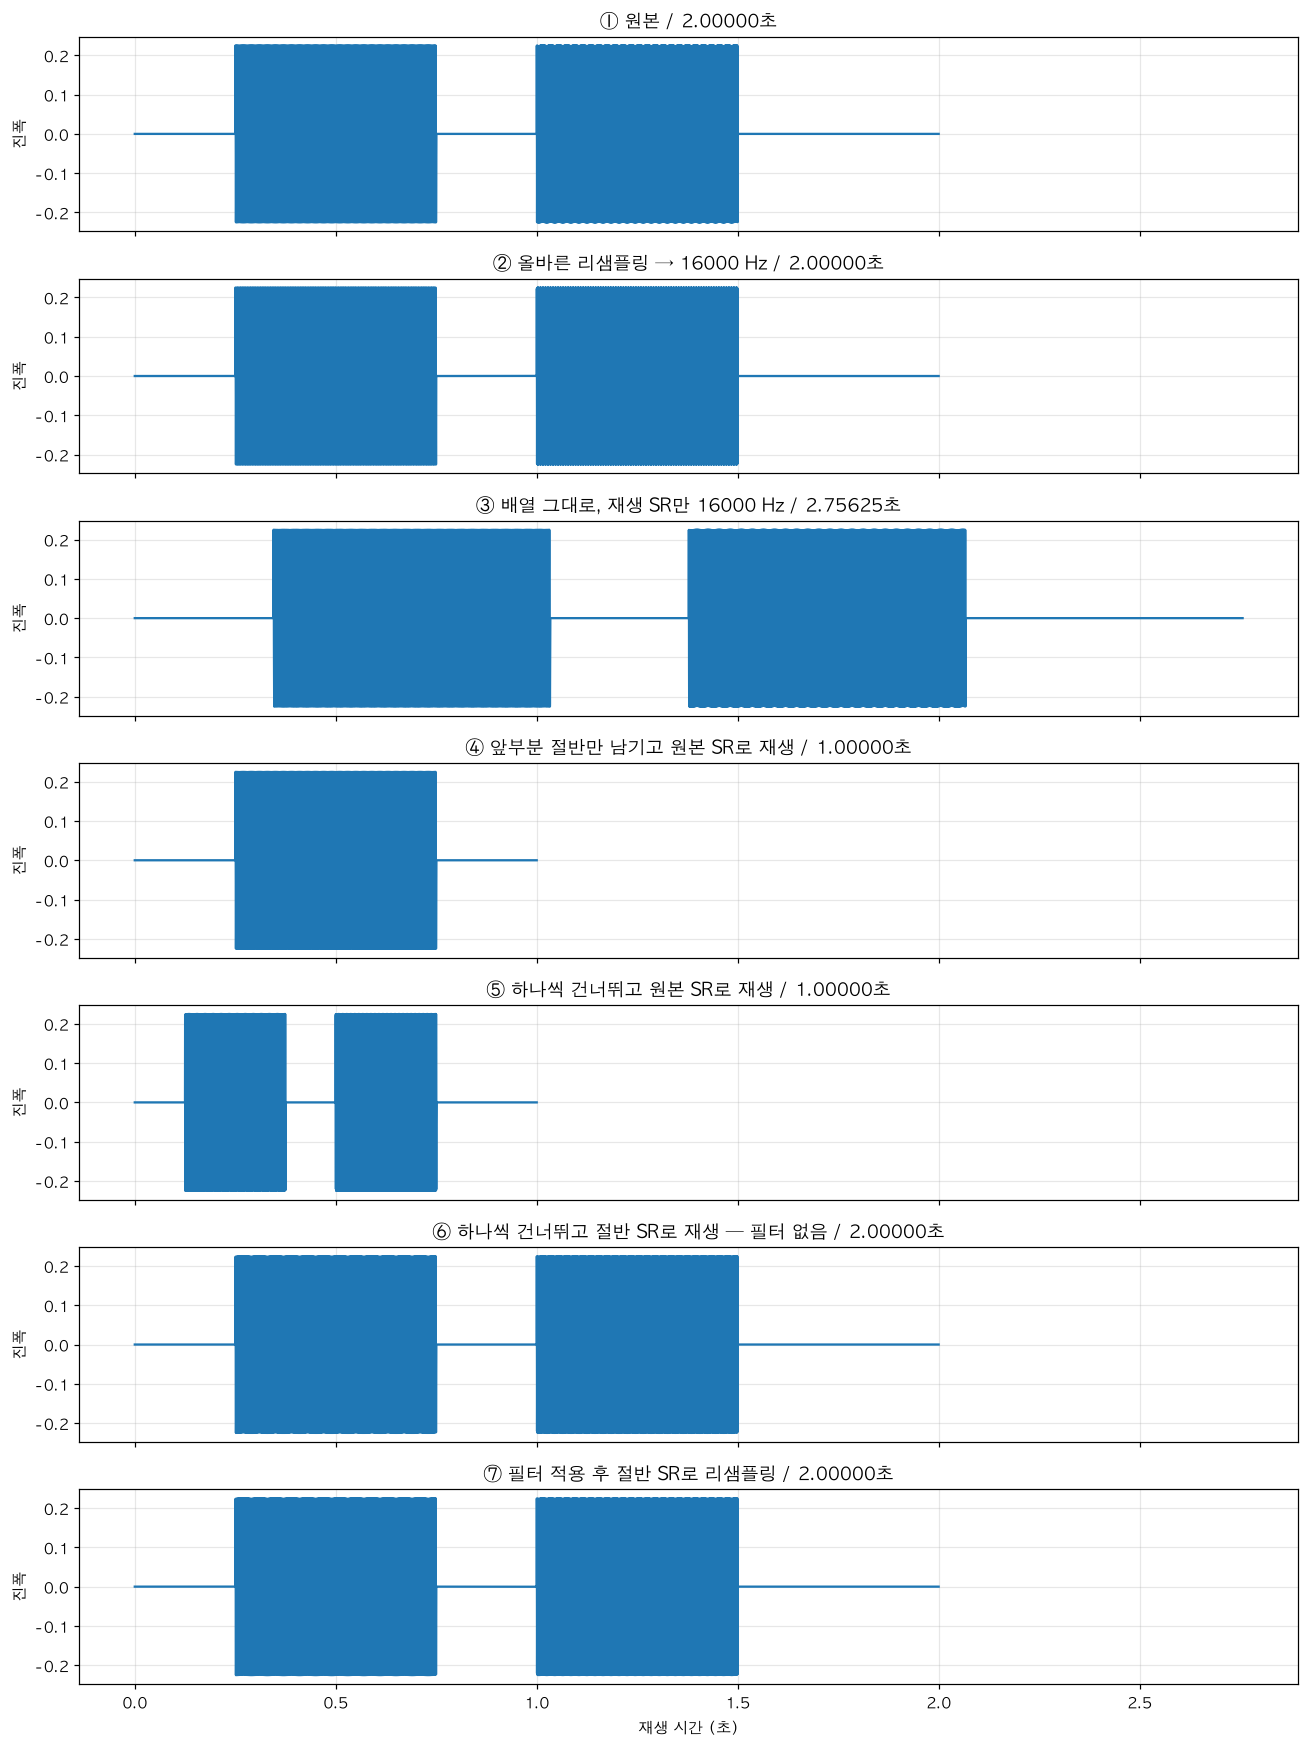

In [92]:
# 모든 그래프의 시간축과 진폭축 범위를 같게 맞춥니다.
fig, axes = plt.subplots(
    len(cases), 1,
    figsize=(12, 16),
    sharex=True,
    sharey=True
)

for ax, (title, sound, rate) in zip(axes, cases):
    # 실제 재생 SR로 시간축을 계산합니다.
    time = np.arange(len(sound)) / rate
    ax.plot(time, sound)

    ax.set_title(f"{title} / {len(sound) / rate:.5f}초")
    ax.set_ylabel("진폭")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("재생 시간 (초)")
plt.tight_layout()
plt.show()

### 실제 음성 실습3. 내 목소리의 sampling rate를 바꾸는 2가지 방법

In [94]:
# 3교시용 실제 음성을 새로 읽습니다. 합성음 변수와 구분합니다.
VOICE_PATH = DATA_DIR / "my_voice.wav"
voice3_path = VOICE_PATH # 개인 원본을 쓰려면 VOICE_PATH로 변경 vs VOICE_STEREO_PATH 강사님 파일
voice3_sr, voice3_source = read_pcm16(voice3_path)
voice3_mono = (voice3_source.mean(axis=1)
               if voice3_source.ndim == 2 else voice3_source)
print("파일:", voice3_path.name)
print("SR:", voice3_sr, "/ 원본 모양:", voice3_source.shape)
print("원래 길이:", len(voice3_mono) / voice3_sr, "초")

파일: my_voice.wav
SR: 44100 / 원본 모양: (351036, 2)
원래 길이: 7.96 초


In [95]:
# [복습 과제] 이 값을 16000으로 바꾸어 이 셀과 다음 비교 셀을 다시 실행하세요.
voice3_target_sr = 24000

# 예상 출력 샘플 수입니다. 끝부분의 불완전한 샘플 간격은 올림합니다.
voice3_expected_n = (len(voice3_mono) * voice3_target_sr + voice3_sr - 1) // voice3_sr
print("예상 리샘플링 샘플 수:", voice3_expected_n)

# SR 비율을 정수로 약분합니다. 48000→24000이면 1/2입니다.
voice3_common = gcd(voice3_sr, voice3_target_sr)
voice3_up = voice3_target_sr // voice3_common
voice3_down = voice3_sr // voice3_common
voice3_resampled = resample_poly(voice3_mono, up=voice3_up, down=voice3_down)

print("비율:", voice3_up, "/", voice3_down)
print("원본:", len(voice3_mono), "개 /", len(voice3_mono)/voice3_sr, "초")
# 잘못된 재생은 배열이 원본 그대로입니다.
print("SR만 변경:", len(voice3_mono), "개 /", len(voice3_mono)/voice3_target_sr, "초")
print("리샘플링:", len(voice3_resampled), "개 /", len(voice3_resampled)/voice3_target_sr, "초")

예상 리샘플링 샘플 수: 191040
비율: 80 / 147
원본: 351036 개 / 7.96 초
SR만 변경: 351036 개 / 14.6265 초
리샘플링: 191040 개 / 7.96 초


In [96]:
voice3_target_sr = 16000

# 예상 출력 샘플 수입니다. 끝부분의 불완전한 샘플 간격은 올림합니다.
voice3_expected_n = (len(voice3_mono) * voice3_target_sr + voice3_sr - 1) // voice3_sr
print("예상 리샘플링 샘플 수:", voice3_expected_n)

# SR 비율을 정수로 약분합니다. 48000→24000이면 1/2입니다.
voice3_common = gcd(voice3_sr, voice3_target_sr)
voice3_up = voice3_target_sr // voice3_common
voice3_down = voice3_sr // voice3_common
voice3_resampled = resample_poly(voice3_mono, up=voice3_up, down=voice3_down)

print("비율:", voice3_up, "/", voice3_down)
print("원본:", len(voice3_mono), "개 /", len(voice3_mono)/voice3_sr, "초")
# 잘못된 재생은 배열이 원본 그대로입니다.
print("SR만 변경:", len(voice3_mono), "개 /", len(voice3_mono)/voice3_target_sr, "초")
print("리샘플링:", len(voice3_resampled), "개 /", len(voice3_resampled)/voice3_target_sr, "초")

예상 리샘플링 샘플 수: 127360
비율: 160 / 441
원본: 351036 개 / 7.96 초
SR만 변경: 351036 개 / 21.93975 초
리샘플링: 127360 개 / 7.96 초


원본
재생 SR만 변경
올바른 리샘플링


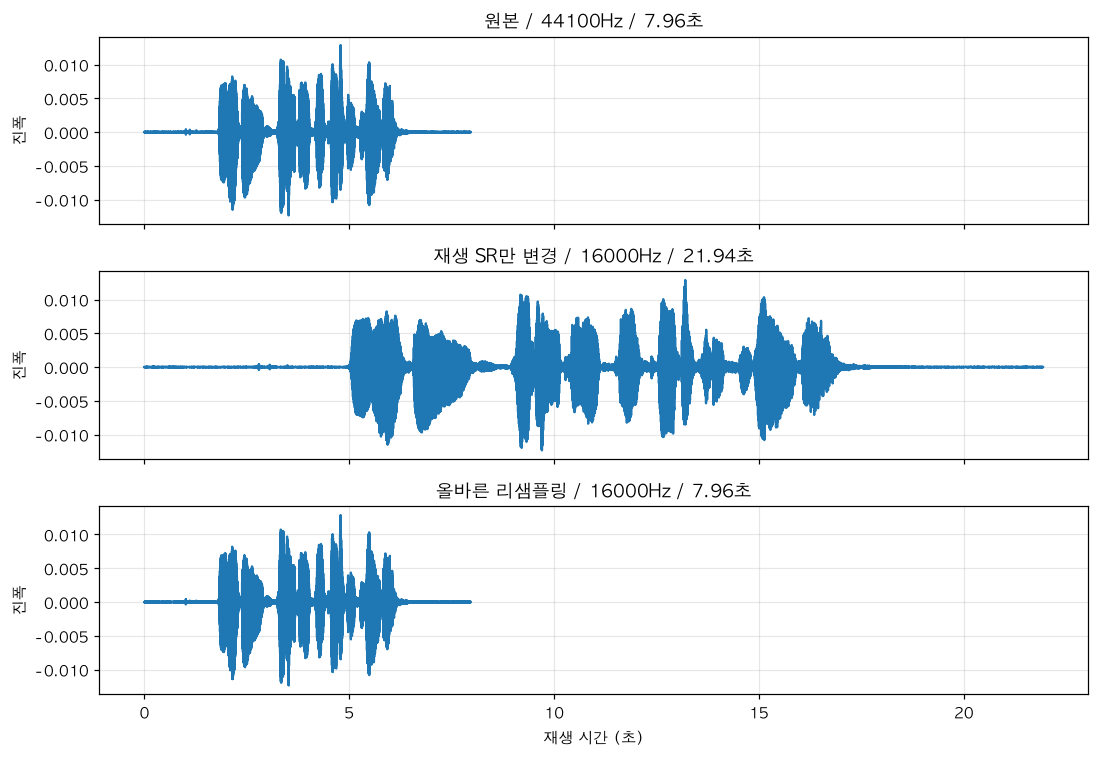

In [106]:
# 같은 배열도 rate를 다르게 지정하면 시간과 음의 높이가 달라집니다.
voice3_cases = [
    ("원본", voice3_mono, voice3_sr),
    ("재생 SR만 변경", voice3_mono, voice3_target_sr),
    ("올바른 리샘플링", voice3_resampled, voice3_target_sr)
]
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, sharey=True)
for ax, (label, sound, rate) in zip(axes, voice3_cases):
    # 각 재생 조건에 맞는 시간축을 사용해야 늘어난 길이를 볼 수 있습니다.
    ax.plot(np.arange(len(sound)) / rate, sound)
    ax.set_title(f"{label} / {rate}Hz / {len(sound)/rate:.2f}초")
    ax.set_ylabel("진폭")
    ax.grid(alpha=0.3)
    print(label)
    # display(Audio(sound, rate=rate, normalize=False))
axes[-1].set_xlabel("재생 시간 (초)")
plt.tight_layout()
plt.show()

# 2026.10.22(목) 21h~

### 실습7. 소리 앞/뒤에 여유를 남겨 자르기

자르기 전: 2.0 초
자르기 후: 1.35 초


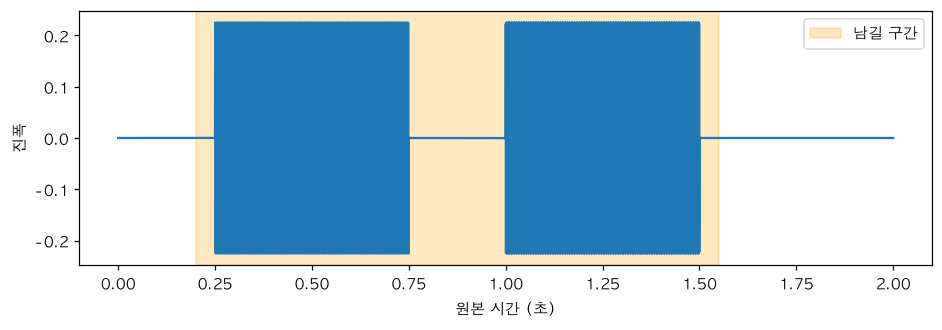

In [98]:
# 앞선 실습에서 사용한 변수값에 영향을 받지 않도록 원본 파일을 다시 읽습니다.
# 원본: SR 22050 Hz, 스테레오 배열 (44100, 2), 길이 2초
crop_tone_sr, crop_tone_stereo = read_pcm16(
    DATA_DIR / "tone_sequence_22050_stereo.wav"
)

# 같은 시각의 왼쪽·오른쪽 값을 평균하여 모노로 만듭니다.
# 배열 모양: (44100, 2) → (44100,)
# 채널만 합치므로 SR과 길이는 그대로입니다.
crop_tone_mono = crop_tone_stereo.mean(axis=1)

# 자르기에 사용할 음성을 16000 Hz로 준비합니다.
crop_tone_target_sr = 16000

# 변환 비율 16000 / 22050을 최대공약수 50으로 약분합니다.
# up = 320, down = 441
crop_tone_g = gcd(crop_tone_sr, crop_tone_target_sr)

# 필터링과 새 샘플 값 계산을 통해 16000 Hz 배열을 만듭니다.
# 샘플 수: 44100개 → 32000개, 길이: 2초 유지
crop_tone_resampled = resample_poly(
    crop_tone_mono,
    up=crop_tone_target_sr // crop_tone_g,
    down=crop_tone_sr // crop_tone_g
)

# 남길 구간: 원본 시간 기준 0.20초 이상 ~ 1.55초 미만
# 첫 소리 시작 전과 마지막 소리 끝난 후에 각각 0.05초의 여유를 둡니다.
crop_tone_start = 0.20
crop_tone_end = 1.55

# 시간을 샘플 인덱스로 바꿉니다: 시간(초) × 현재 배열의 SR
# 현재 배열은 리샘플링했으므로 원본 SR 22050이 아닌 16000을 사용합니다.
# round()로 가장 가까운 샘플 위치를 선택하고 int()로 정수 인덱스를 만듭니다.
crop_tone_i = int(round(crop_tone_start * crop_tone_target_sr))  # 3200
crop_tone_j = int(round(crop_tone_end * crop_tone_target_sr))    # 24800

# 시작 인덱스 3200은 포함하고, 끝 인덱스 24800은 제외합니다.
# 선택한 샘플 수: 24800 - 3200 = 21600개
# 결과 길이: 21600 / 16000 = 1.35초
# 선택 구간 안의 소리와 중간의 쉼은 그대로 남습니다.
crop_tone_trimmed = crop_tone_resampled[crop_tone_i:crop_tone_j]

print("자르기 전:", len(crop_tone_resampled) / crop_tone_target_sr, "초")
print("자르기 후:", len(crop_tone_trimmed) / crop_tone_target_sr, "초")

# 자르기 전의 전체 파형을 표시합니다.
# 샘플 번호를 현재 SR로 나누어 초 단위 시간축을 만듭니다.
plt.figure()
plt.plot(
    np.arange(len(crop_tone_resampled)) / crop_tone_target_sr,
    crop_tone_resampled
)

# 남길 구간을 반투명 주황색으로 표시합니다.
# axvspan()은 표시만 하며, 실제 자르기는 위의 배열 슬라이싱에서 수행합니다.
plt.axvspan(
    crop_tone_start,
    crop_tone_end,
    color="orange",
    alpha=0.25,
    label="남길 구간"
)

plt.xlabel("원본 시간 (초)")
plt.ylabel("진폭")
plt.legend()
plt.show()

# 잘라낸 1.35초 구간을 현재 SR인 16000 Hz로 재생합니다.
# normalize=False: 자동으로 소리 크기를 조정하지 않습니다.
# 이 코드는 재생만 하며, WAV 파일로 저장하지는 않습니다.
display(Audio(
    crop_tone_trimmed,
    rate=crop_tone_target_sr,
    normalize=False
))

### Q. `axvspan()`은 정확히 무엇을 하는 메서드인가? (Matplotlib 것이 맞나?)

**한 줄 답:** 네, **Matplotlib**의 메서드입니다. 그래프에서 **세로 방향으로 쭉 뻗은 색칠된 띠(직사각형)** 를 그려서 "가로축(x)의 이 구간"을 **표시**하는 기능입니다. 데이터는 바꾸지 않고 그림 위에 색만 얹습니다.

확인한 환경: Matplotlib `3.11.2`(이 `voice-ai` 환경). 아래 정의와 동작은 이 버전의 도움말(`help`)과 직접 실행한 결과입니다. 오래된 버전(3.9 미만)은 반환 형태가 다를 수 있습니다(일반 지식).

#### 1. 이름의 뜻
`ax` + `v` + `span` = **Axes(그래프 영역) 위에 세로(vertical)로 걸치는(span) 띠**. 비슷한 이름을 한 묶음으로 기억하면 편합니다.

| 메서드 | 그리는 것 | 이 노트북 / 앞 수업의 사용 |
|---|---|---|
| `axvspan(xmin, xmax)` | x 구간을 **세로 띠**로 칠함 | 이 셀의 "남길 구간" |
| `axvline(x)` | x 위치에 **세로 선 1개** | 01 노트북의 `plt.axvline(k * period_ms, …)` |
| `axhspan(ymin, ymax)` | y 구간을 **가로 띠**로 칠함 | 사용하지 않음(일반 지식) |

#### 2. 정의 (공식 도움말 기준)
```python
plt.axvspan(xmin, xmax, ymin=0, ymax=1, **kwargs)   # 반환값: Rectangle(직사각형 도형)
```
| 인자 | 뜻 | 단위 |
|---|---|---|
| `xmin` | 띠의 **왼쪽** 끝 | **데이터 단위**(이 그래프에서는 초) |
| `xmax` | 띠의 **오른쪽** 끝 | 데이터 단위(초) |
| `ymin` | 띠의 **아래** 끝, 기본 `0` | **축 비율 0~1** (0 = 맨 아래, 1 = 맨 위). 데이터 값이 아님 |
| `ymax` | 띠의 **위** 끝, 기본 `1` | 축 비율 0~1 |
| `color`, `alpha`, `label` 등 | 색, 투명도, 범례 이름 같은 모양 설정 | `Rectangle`의 속성들 |

- 그래서 `ymin`, `ymax`를 안 쓰면 **그래프의 위에서 아래까지 전체 높이**를 덮습니다. 직접 확인: y축 범위를 `-5~5`로 바꿔도 띠는 여전히 `-5`에서 `5`까지 덮었습니다. 높이가 비율이라 y축 범위가 바뀌어도 "전체 높이"를 유지합니다.
- `plt.axvspan(...)`은 **지금 그리고 있는 그래프**(`gca()`)에 그리는 간편 호출이고, `axes[0].axvspan(...)`처럼 **특정 그래프에 직접** 부를 수도 있습니다. 이 노트북에서 위 셀은 앞의 방식, 83번 셀 근처의 자르기 실습은 뒤의 방식을 씁니다. 하는 일은 같습니다.

#### 3. 이 셀의 호출 읽기
```python
plt.axvspan(
    crop_tone_start,   # 0.20  → 띠의 왼쪽 끝(초)
    crop_tone_end,     # 1.55  → 띠의 오른쪽 끝(초)
    color="orange",    # 주황색
    alpha=0.25,        # 투명도 25% (파형이 비쳐 보임. 1이면 불투명, 0이면 안 보임)
    label="남길 구간"   # plt.legend()가 이 이름으로 범례를 만듦
)
```
- 가로축이 **시간(초)** 이므로 `0.20`~`1.55`초 구간이 주황색으로 칠해집니다. 아래쪽 `plt.legend()`가 이 `label`을 범례에 보여 줍니다(직접 확인: 범례에 `남길 구간`이 나타남).
- **자르기는 하지 않습니다.** 셀 주석에도 있듯이 실제 자르기는 위의 `crop_tone_resampled[crop_tone_i:crop_tone_j]`(배열 슬라이싱)에서 일어나고, `axvspan`은 "여기를 남길 것"이라는 **표시**일 뿐입니다. 이 호출을 지워도 `crop_tone_trimmed`는 똑같이 만들어집니다.

#### 4. 알아 둘 점 (★)
- **x 값은 "시간(초)"으로 줘야 합니다.** 이 그래프의 가로축을 `샘플 번호 ÷ SR`(초)로 만들었기 때문입니다. 샘플 **번호**(예: 3200)를 그대로 넣으면 3200초 위치를 칠하려고 해서 그래프가 이상해집니다. 그래서 83번 셀 근처에서는 `voice4_start_index/voice4_target_sr`처럼 번호를 SR로 나눠 초로 바꿔서 넣습니다.
- **그래프에 보이는 데이터 범위 밖의 x를 주면** 가로축 범위가 그만큼 넓어집니다. 직접 실험: 데이터가 `0~2`일 때 `axvspan(5, 6)`을 그리자 가로축이 `-0.1~2.1`에서 `-0.3~6.3`으로 넓어졌습니다. 세로 범위는 그대로였습니다.
- 지금 `crop_tone_start`/`crop_tone_end`는 **원본 시간 기준**입니다. 리샘플링해도 길이(초)는 같으므로 같은 초 값을 쓸 수 있고, 인덱스로 바꿀 때만 `현재 배열의 SR`(16000)을 곱합니다.


### 실습8. PCM16으로 저장하고 다시 읽기

실수 -> 정수 파일로 변환 및 저장?

In [100]:
RESULT_DIR.mkdir(exist_ok=True)
tone_output_path = RESULT_DIR / "tone_processed.wav"
if not np.all(np.isfinite(crop_tone_trimmed)) or np.max(np.abs(crop_tone_trimmed)) > 1:
    raise ValueError("저장할 값이 유한한 수이며 -1~1 범위인지 확인하세요.")
# np.rint(): 반올림. np.clip(): 정수 PCM16의 범위 안으로 제한.
# +1 × 32768은 32768이므로 최댓값 32767에 맞춥니다.
tone_pcm = np.clip(np.rint(crop_tone_trimmed * 32768), -32768, 32767).astype(np.int16)
wavfile.write(tone_output_path, crop_tone_target_sr, tone_pcm)

# 저장 후 실제 파일을 다시 읽어 SR·채널·자료형·길이를 확인합니다.
tone_check_sr, tone_check_raw = wavfile.read(tone_output_path)
print("저장 파일:", tone_output_path)
print("SR:", tone_check_sr, "/ 모양:", tone_check_raw.shape, "/ 자료형:", tone_check_raw.dtype)
print("길이:", len(tone_check_raw)/tone_check_sr, "초")
tone_check_float = tone_check_raw.astype(np.float32)/32768.0
print("정수 눈금 변환에 따른 최대 차이:", np.max(np.abs(crop_tone_trimmed-tone_check_float)))
display(Audio(tone_check_float, rate=tone_check_sr, normalize=False))

저장 파일: results/tone_processed.wav
SR: 16000 / 모양: (21600,) / 자료형: int16
길이: 1.35 초
정수 눈금 변환에 따른 최대 차이: 1.5258789e-05


### Q. `crop_tone_trimmed`는 "실수 음성 **파일**"인가? 근거는?

**한 줄 답:** `crop_tone_trimmed`는 **파일이 아니라 메모리 안의 NumPy 배열**이고, 그 안의 숫자는 **실수(`float32`)** 입니다. 파일은 이 셀이 `results/tone_processed.wav`로 **새로 저장한 것**이고, 그 파일 안의 숫자는 **정수(`int16`)** 입니다.

#### 1. 세 가지를 구분하세요
| 이름 | 종류 | 숫자 종류 | 어디에 있나 |
|---|---|---|---|
| `crop_tone_trimmed` | **배열(변수)** | **실수** `float32`, 모양 `(21600,)` | 컴퓨터 메모리(노트북을 닫으면 사라짐) |
| `results/tone_processed.wav` | **파일** | **정수** `int16`, 모양 `(21600,)` | 하드디스크 |
| `tone_check_float` | 배열(변수) | 실수 `float32` | 메모리. 저장한 파일을 다시 읽어서 `÷32768`한 것 |

"파일"이라는 말은 디스크에 저장된 `.wav`를 가리킬 때만 씁니다. `crop_tone_trimmed`는 77번 셀 주석에도 있듯이 **"WAV 파일로 저장하지는 않는다"**(재생만 함). 파일로 저장하는 것은 아래 79번 셀의 `wavfile.write(...)`입니다.

#### 2. `crop_tone_trimmed`가 실수(`float32`)라는 근거
**(가) 만들어진 과정을 따라가면 실수입니다** (77번 셀):
1. `read_pcm16(...)` → 안에서 `integers.astype(np.float32) / 32768.0` → **실수 배열**을 돌려줍니다.
2. `.mean(axis=1)` → 실수끼리 평균 → 실수 (`float32` 유지).
3. `resample_poly(...)` → 필터로 새 값을 계산하므로 소수점 값이 나옵니다(`float32` 입력이면 `float32`).
4. `crop_tone_resampled[3200:24800]` → 슬라이싱(자르기)은 **값과 자료형을 바꾸지 않고** 그 구간을 골라낼 뿐입니다.

**(나) 이 코드를 그대로 실행해서 확인했습니다** (직접 실행한 결과):
- `crop_tone_trimmed.dtype` → `float32`, `crop_tone_trimmed.shape` → `(21600,)`
- 값의 범위: 최소 `-0.2253`, 최대 `+0.2253` → 소수점이 있는 값이고 −1~1 안
- 앞쪽 값: `0.0000351674`, `-0.0387113`, `-0.0763018` … → 정수가 아님

**(다) 79번 셀 코드 자체가 실수임을 전제로 쓰였습니다:**
- `np.max(np.abs(crop_tone_trimmed)) > 1` → "−1~1 범위인지" 검사 = 실수 눈금의 기준입니다. 정수 PCM이었다면 범위가 −32768~32767이라 이 검사가 의미가 없습니다.
- `crop_tone_trimmed * 32768` → **실수를 정수 눈금으로 확대**합니다. 이미 정수였다면 곱할 필요가 없습니다.
- `.astype(np.int16)`이 **그 다음에** 나옵니다. 정수로 바꾸는 단계가 따로 필요하다는 건, 그 전까지는 정수가 아니었다는 뜻입니다.

#### 3. 79번 셀이 하는 일 (실수 배열 → 정수 파일)
```text
crop_tone_trimmed          (float32, -1~1)      ← 메모리의 실수 배열
      │  × 32768           정수 눈금으로 확대        예: -0.0387113 → -1268.49…
      │  np.rint(...)      반올림                   → -1268
      │  np.clip(...)      -32768~32767로 제한      (넘는 값은 잘라냄)
      │  .astype(np.int16) 정수 자료형으로 변환     → tone_pcm
      ▼
wavfile.write(...)         → results/tone_processed.wav (int16, 하드디스크)
```
직접 확인한 예: 실수 `-0.0387113` × 32768 = `-1268.4915` → 반올림 `-1268`(파일에는 이 정수가 저장됨).

#### 4. 출력 `정수 눈금 변환에 따른 최대 차이: 1.5258789e-05`의 뜻
- 저장할 때 반올림하면서 값이 **최대 0.5칸**(= 0.5 ÷ 32768 = `0.0000152587…`) 달라집니다. 출력 `1.5258789e-05`가 정확히 그 값입니다(직접 확인).
- 즉 "실수 → 정수로 저장 → 다시 실수로 읽기" 과정에서 생기는 **반올림 오차**이고, 소리로는 거의 들리지 않는 크기입니다(0.3 진폭 대비 약 0.005%).
- `e-05`는 `× 10⁻⁵`를 뜻하는 지수 표기입니다: `1.5258789e-05 = 0.000015258789`.
- 이 오차 때문에 **파일을 다시 읽은 값(`tone_check_float`)은 원래 실수 배열(`crop_tone_trimmed`)과 정확히 같지 않습니다.** 정수는 1/32768 간격의 눈금에만 있을 수 있기 때문입니다.

#### 5. 직접 확인해 보는 코드 (새 셀에 한 줄씩)
```python
print(crop_tone_trimmed.dtype)      # float32 → 실수 배열
print(tone_pcm.dtype)               # int16   → 파일에 저장할 정수 배열
print(tone_check_raw.dtype)         # int16   → 저장한 파일을 읽은 것
print(tone_check_float.dtype)       # float32 → 다시 실수로 바꾼 것
print(type(crop_tone_trimmed))      # numpy.ndarray → 파일이 아니라 배열
```


In [102]:
print(crop_tone_trimmed.dtype)      # float32 → 실수 배열
print(tone_pcm.dtype)               # int16   → 파일에 저장할 정수 배열
print(tone_check_raw.dtype)         # int16   → 저장한 파일을 읽은 것
print(tone_check_float.dtype)       # float32 → 다시 실수로 바꾼 것
print(type(crop_tone_trimmed))      # numpy.ndarray → 파일이 아니라 배열

float32
int16
int16
float32
<class 'numpy.ndarray'>


### 실제 음성 실습4. 내 발화 구간을 선택하고 제출 파일 만들기

내 목소리 녹음 파일 앞/뒤 조용한 구간 자르기

#### 이 셀의 숫자 풀이 (위 64번 셀 아래 설명 참고)
- 원본 `44100 Hz` → 목표 `16000 Hz`, `gcd(44100, 16000) = 100` → **`up = 160`, `down = 441`**
- 새 샘플 수 = `351036 × 160 ÷ 441 = 127360` → 출력 `127360개`와 같음
- 길이 = `127360 ÷ 16000 = 7.96초` → 원본 길이(`351036 ÷ 44100 = 7.96초`)와 같음
- 목표 SR의 절반 `8000 Hz`보다 높은 소리는 필터가 제거합니다. 사람 말소리의 중요한 정보는 대부분 8000 Hz 아래에 있다는 점이 16000 Hz를 쓰는 이유로 흔히 설명됩니다(일반 지식, 이 노트북에서 확인하지 않음).


원본: my_voice.wav / 44100 Hz / 2 채널
원본 길이: 7.96 초
준비한 배열: 127360 개 / 16000 Hz / 7.96 초


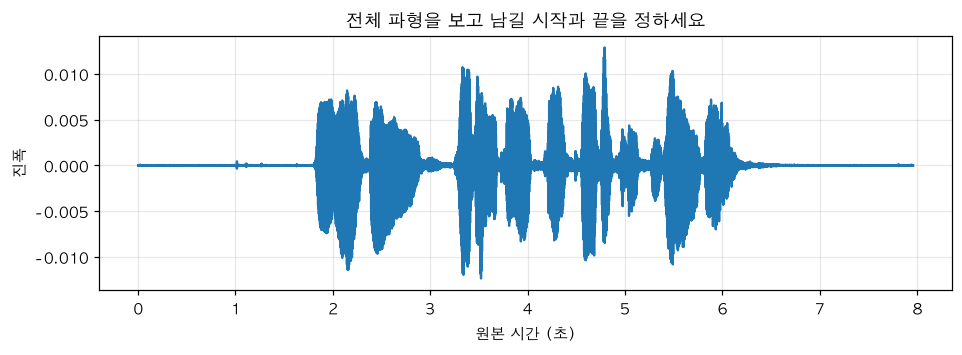

In [107]:
voice4_path = VOICE_PATH
voice4_sr, voice4_source = read_pcm16(voice4_path)
voice4_channels = 1 if voice4_source.ndim == 1 else voice4_source.shape[1]
voice4_mono = (voice4_source.mean(axis=1)
               if voice4_source.ndim == 2 else voice4_source.copy())
voice4_target_sr = 16000
voice4_g = gcd(voice4_sr, voice4_target_sr)
voice4_resampled = resample_poly(voice4_mono,
                               up=voice4_target_sr // voice4_g,
                               down=voice4_sr // voice4_g)
voice4_duration = len(voice4_resampled) / voice4_target_sr
print("원본:", voice4_path.name, "/", voice4_sr, "Hz /", voice4_channels, "채널")
print("원본 길이:", len(voice4_mono)/voice4_sr, "초")
print("준비한 배열:", len(voice4_resampled), "개 /", voice4_target_sr, "Hz /", voice4_duration, "초")
plt.figure(figsize=(10, 3))
plt.plot(np.arange(len(voice4_resampled))/voice4_target_sr, voice4_resampled)
plt.xlabel("원본 시간 (초)")
plt.ylabel("진폭")
plt.title("전체 파형을 보고 남길 시작과 끝을 정하세요")
plt.grid(alpha=0.3)
plt.show()
# display(Audio(voice4_resampled, rate=voice4_target_sr, normalize=False))

시작 인덱스: 28000 / 끝 인덱스(제외): 100800
자르기 전: 7.96 초
자르기 후: 4.55 초


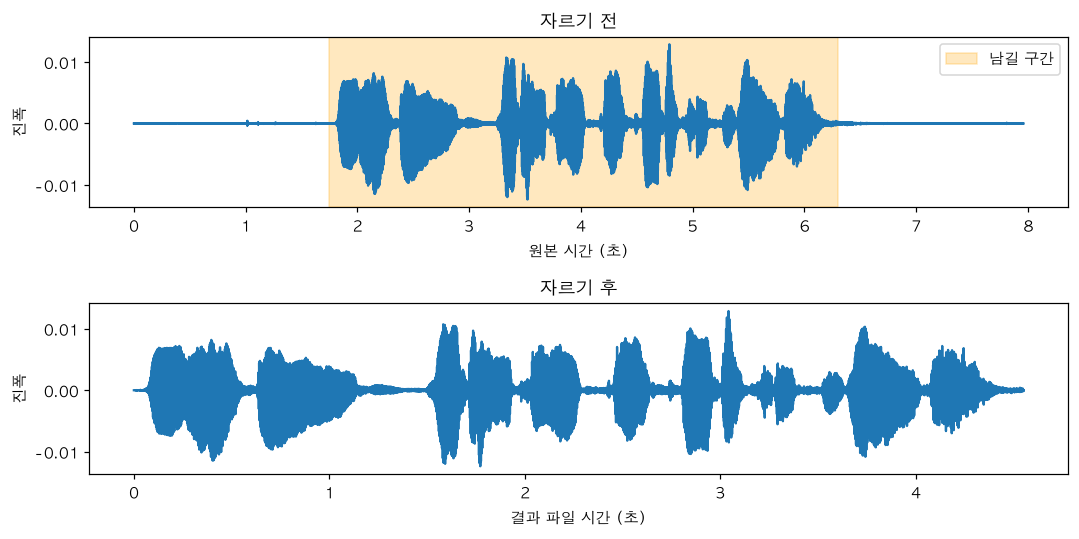

자르기 전
자르기 후: 단어의 시작과 끝이 보존되었는지 직접 들으세요.


In [108]:
# voice4_start_seconds = 1.00 # 강사님 파일
# voice4_end_seconds = 3.60 # 강사님 파일
voice4_start_seconds = 1.75
voice4_end_seconds = 6.30 
if not (0 <= voice4_start_seconds < voice4_end_seconds <= voice4_duration):
    raise ValueError("0 ≤ 시작 < 끝 ≤ 전체 길이가 되도록 시간을 수정하세요.")

# 현재 배열은 16000Hz입니다. 원본의 48000Hz를 쓰면 안 됩니다.
voice4_start_index = int(round(voice4_start_seconds * voice4_target_sr))
voice4_end_index = int(round(voice4_end_seconds * voice4_target_sr))
if not (0 <= voice4_start_index < voice4_end_index <= len(voice4_resampled)):
    raise ValueError("선택 구간에 최소 한 샘플이 들어가도록 시간을 조정하세요.")

# 시작은 포함, 끝은 제외합니다. 소리를 늘이거나 줄이지 않고 구간만 선택합니다.
voice4_trimmed = voice4_resampled[voice4_start_index:voice4_end_index]
print("시작 인덱스:", voice4_start_index, "/ 끝 인덱스(제외):", voice4_end_index)
print("자르기 전:", voice4_duration, "초")
print("자르기 후:", len(voice4_trimmed)/voice4_target_sr, "초")

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharey=True)
axes[0].plot(np.arange(len(voice4_resampled))/voice4_target_sr, voice4_resampled)
axes[0].axvspan(voice4_start_index/voice4_target_sr, voice4_end_index/voice4_target_sr,
               color="orange", alpha=0.25, label="남길 구간")
axes[0].set(title="자르기 전", xlabel="원본 시간 (초)", ylabel="진폭")
axes[0].legend()
# 결과 배열의 첫 샘플은 새 파일에서 0초가 됩니다.
axes[1].plot(np.arange(len(voice4_trimmed))/voice4_target_sr, voice4_trimmed)
axes[1].set(title="자르기 후", xlabel="결과 파일 시간 (초)", ylabel="진폭")
plt.tight_layout()
plt.show()
print("자르기 전")
# display(Audio(voice4_resampled, rate=voice4_target_sr, normalize=False))
print("자르기 후: 단어의 시작과 끝이 보존되었는지 직접 들으세요.")
# display(Audio(voice4_trimmed, rate=voice4_target_sr, normalize=False))

## 2026-10-22(목) 수업 리뷰 — 02 노트북 마무리 (SR·리샘플링·자르기·저장)

수치는 노트북의 파일(`data/…`)과 코드를 직접 실행해서 계산했습니다. 추정·일반 지식은 따로 표시했습니다.

### 1. 오늘 02에서 진행한 내용 (셀 기준)
| 셀 | 내용 | 한 줄 평가 |
|---|---|---|
| 61 | 같은 배열을 **틀린 SR(8000)** 로 재생 | 2.0초 → **4.0초**, 의도대로 나옴 ✓ |
| 64~70 | 22050 → 16000 리샘플링과 7가지 비교(①~⑦) | 샘플 수 44100 → 32000, 길이 2.0초 유지 ✓ |
| 72~75 | **내 목소리**로 같은 비교 (24000 → 16000 복습 과제 포함) | 아래 2번 참고 ✓ |
| 78 | 소리 앞뒤 여유를 남겨 자르기 (0.20~1.55초) | 3200 ~ 24800, 21600개, 1.35초 ✓ |
| 81 | 실수 → `int16` 저장 → 다시 읽기 | 최대 차이 `1.5258789e-05` = 0.5 ÷ 32768 ✓ |
| 87 | **내 녹음** 자르기 (1.75~6.30초) | 28000 ~ 100800, 4.55초 ✓ (아래 3번) |

### 2. 실행 결과에서 눈여겨볼 것
**(1) SR만 바꿔 재생하면 길이와 음 높이가 함께 변합니다 (③번, 75번)**
- 합성음 ③: 샘플 44100개를 16000 Hz로 재생 → `44100 ÷ 16000 = 2.75625초` (출력과 일치). 음이 낮아지는 비율은 `16000 ÷ 22050 = 0.7256`이라 **440 Hz가 약 319 Hz, 880 Hz가 약 639 Hz로 들려야 합니다.** 반음으로 약 **-5.55** (`12 × log₂(0.7256)`)입니다. (계산값이며 FFT로 확인하지는 않았습니다.)
- 내 목소리: 44100 Hz 녹음을 16000 Hz로 재생 → `7.96 → 21.94초`(2.76배), 약 **-17.55 반음**(1옥타브 + 약 5.5반음 낮음). "느리고 낮고 괴물 같은 소리"가 들렸다면 정상입니다.
- 올바른 리샘플링(②, 75번 셋째)은 **길이 7.96초가 그대로**입니다. 이게 SR만 바꾸는 것과의 핵심 차이입니다.

**(2) 복습 과제(24000 → 16000)의 비율 계산이 맞습니다**
| 목표 SR | 약분 | 새 샘플 수 계산 | 출력 |
|---|---|---|---|
| 24000 | 80 / 147 | 351036 × 80 ÷ 147 = 191040 | **191040** ✓ |
| 16000 | 160 / 441 | 351036 × 160 ÷ 441 = 127360 | **127360** ✓ |
- 둘 다 `예상 샘플 수`(올림 공식)와 실제 길이가 일치했습니다.

**(3) ⑥번(필터 없이 건너뛰기)과 ⑦번(필터 적용)이 이 합성음에서는 거의 똑같이 들립니다**
- 직접 비교: 소리가 한창 나는 구간의 최대 차이 `0.0002`(소리 크기 RMS `0.1125`의 0.2%), 소리가 켜지고 꺼지는 모서리에서만 최대 `0.009`입니다.
- 이유(추정이 아닌 계산): 합성음은 **440 Hz와 880 Hz**뿐이라 새 SR의 절반(`11025 ÷ 2 = 5512.5 Hz`)보다 훨씬 낮습니다. 필터가 지울 높은 소리가 없으니 차이가 없습니다. **그래서 이 실험으로는 "필터가 왜 필요한가"가 보이지 않습니다.**
- 필터의 효과를 보려면 **5512.5 Hz보다 높은 소리**가 필요합니다. 직접 확인: 22050 Hz로 만든 **8000 Hz** 사인파를 절반 SR로 바꾸면
  - 그냥 건너뛰기: 소리가 사라지지 않고 **`11025 − 8000 = 3025 Hz`** 로 둔갑해 크기가 그대로(`0.15`) 남음
  - 필터 적용(`resample_poly`): 크기 `0.0001`로 거의 제거
  - 해 보려면 `np.sin(2*np.pi*8000*n/22050)` 배열로 ⑥번과 ⑦번 방식을 비교해 보세요.

**(4) 내 목소리는 16 kHz로 줄여도 잃는 정보가 적습니다 (이 녹음 기준)**
- 에너지의 **99.92%** 가 8000 Hz 아래이고, 가장 센 주파수는 약 **250 Hz**입니다(직접 계산).
- 주의: 이것은 "소리 에너지" 이야기이고, 음성 인식 정확도가 같다는 보장은 아닙니다.

### 3. 내 녹음 자르기(87번) 점검
- 말이 시작하는 시점이 약 **1.8초**, 끝나는 시점이 약 **6.1초**입니다(50 ms 단위 RMS가 배경 잡음의 4배를 넘는 구간으로 잰 값, 내 기준).
- 선택한 구간 `1.75~6.30초`의 **앞 여유 약 0.05초, 뒤 여유 약 0.2초**입니다.
- 잘려 나간 **바깥쪽의 최대 크기**는 앞 `0.00045`, 뒤 `0.00029`로, 안쪽 최대 `0.0129`의 3.5% 이하입니다 → **말이 잘리지는 않았습니다.** 잘 맞춘 값입니다.
- 앞뒤 여유가 서로 다른 것(0.05초 vs 0.2초)은 선택 사항입니다. 강사님은 "시작 전과 끝난 후에 각각 같은 정도의 여유"로 설명한 합성음 예(0.05초씩)를 보였습니다.
- **소리가 작습니다.** 최대 크기가 0.0129(전체 범위의 1.3%)입니다. 나중에 정규화(볼륨 맞추기)가 필요한 이유입니다. 단순히 크게 곱하면 잡음도 같이 커진다는 점을 기억하세요(일반 지식).

### 4. 파일 정리 / 커밋 전 점검 (★)
- **내 목소리 재생기가 다시 들어 있습니다**(75번 3개, 86번 1개, 87번 2개). 어제 출력을 지웠는데 오늘 다시 실행해서 생긴 것으로, 파일이 약 **6.2 MB**가 됐습니다. 커밋 전에 출력 지우기를 권합니다. 합성음 재생기만 남기고 싶다면 목소리 셀만 골라서 지우세요.
- **내 컴퓨터 경로가 찍힌 출력**이 54번 셀(잡음 파일 "저장 위치")에 있습니다.
- **오류 출력 1개**: 12번 셀("나의 시도")의 `AttributeError`가 그대로 있습니다. 수정은 하지 않았습니다.
- 비어 있거나 제목이 임시인 셀: `## (제목?)`(67번), `## (내 목소리로 실습)`(71번), 빈 코드 셀 여러 개. 복습할 때 제목을 정리하면 목차로 쓰기 좋습니다.
- 72번 셀이 `VOICE_PATH = DATA_DIR / "my_voice.wav"`로 다시 지정해서, 앞서 지적한 "강사님 파일로 덮어써지는 문제"가 오늘 부분에서는 해결돼 있습니다.

### 5. 수업을 놓친 부분에 대해
- 59번 셀 메모대로 앞 10분을 못 들었다면, 보강 순서로 **61번 셀 앞의 SR과 주파수 설명(57번 md)** → **61번 셀**을 먼저 읽어 보세요. 어떤 내용이 빠졌는지는 제가 알 수 없습니다(강의 녹화본이 있다면 그 구간을 확인하세요).
- 리샘플링의 `up`/`down`, `axvspan`, 실수 → 정수 저장은 이미 각각 설명 셀을 추가해 두었습니다(65, 79, 82번 근처).
